# ABC Credit Loan Approval Chatbot — Data, Pipeline and Model Notebook

**Course:** Predictive and Generative Artificial Intelligence (PGPEM, IIM Bangalore) · **Deliverables 1 and 2 of Section 9**

This notebook is the reproducible record of the *predictive* half of the project. Run top to bottom, it

1. audits the data and documents every quality issue found (Section 6 of the brief);
2. builds one cleaning + feature + encoding pipeline that is reused unchanged by training, batch scoring and the chatbot;
3. **handles the class imbalance** (5.3% DECLINED) at five levels — splitting, metrics, training-time strategies, probability calibration and the decision threshold;
4. selects the minimal set of chatbot questions, tunes and evaluates the model on a 20% hold-out that is never used for any choice;
5. saves the trained pipeline, its metadata and the master data the chatbot needs, and writes the predictions file.

Everything is seeded (`SEED = 42`). The chatbot itself (question flow, model call, PII masking, logging) lives in the `chatbot/` package and loads the artifacts saved here.

| Section | Content |
|---|---|
| 1 | Setup and shared pipeline module |
| 2 | Load and first look |
| 3 | Data-quality audit |
| 4 | Exploratory analysis against the target |
| 5 | Cleaning and feature pipeline |
| 6 | Train / hold-out split |
| 7 | Baselines and model comparison |
| 8 | Handling class imbalance |
| 9 | Selecting the minimal set of questions |
| 10 | Hyper-parameter tuning |
| 11 | Calibration and decision threshold |
| 12 | Hold-out evaluation |
| 13 | Explainability and fairness |
| 14 | Final model, artifacts and robustness test |
| 15 | Predictions file |
| 16 | Scoring latency and results summary |

## 1. Setup and shared pipeline module

In [1]:
import os, sys, json, time, hashlib, warnings, platform, importlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
import sklearn, lightgbm, imblearn, joblib

SEED = 42
FAST = os.environ.get("ABC_FAST") == "1"          # smoke-test switch; the submitted run uses FAST = False
DATA = "data/training_data.csv"
for d in ("artifacts", "figures", "outputs", "logs"):
    os.makedirs(d, exist_ok=True)
RESULTS = {}                                       # every number quoted in the report is stored here

# One visual system for all charts: thin marks, recessive axes, colour used for meaning only
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", ink="#0b0b0b", ink2="#52514e",
         grid="#e4e3de", surface="#fcfcfb", pale="#b7d3f6", red="#d03b3b")
plt.rcParams.update({"figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "font.family": "DejaVu Sans", "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": C["grid"], "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"], "ytick.color": C["ink2"],
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False, "lines.linewidth": 2, "figure.dpi": 110})
def save(fig, name):
    fig.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight"); plt.show()
def pct(ax, axis="y", decimals=0):
    from matplotlib.ticker import PercentFormatter
    getattr(ax, axis + "axis").set_major_formatter(PercentFormatter(1.0, decimals=decimals))

print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| lightgbm", lightgbm.__version__, "| imbalanced-learn", imblearn.__version__)

python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | lightgbm 4.7.0 | imbalanced-learn 0.14.2


### 1.1 The shared module `abc_features.py`

All cleaning, feature engineering and encoding live in one importable module so that **training, batch scoring and the chatbot run exactly the same code** (no training–serving skew), and so that the saved pipeline can be un-pickled by the chatbot. The next cell writes that module; the rest of the notebook imports it.

In [2]:
%%writefile abc_features.py
"""ABC Credit - cleaning, feature engineering and model pipeline.

One module shared by the training notebook, the batch scorer and the chatbot,
so every application is cleaned and encoded by exactly the same code
(no training-serving skew). All fitted steps live inside a scikit-learn Pipeline.
"""
from __future__ import annotations

import re
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, TargetEncoder

SEED = 42
TARGET = "Decision"
POSITIVE = "DECLINED"            # positive class = the event we want to catch
RAW_COLUMNS = ["ID", "Qualifications", "Employment_Type", "Age", "Pincode", "Gender",
               "Product_Code", "Loan_Amount", "LTV", "Resident_Type", "Net_salary",
               "Final_Tier", "Make_Code", "Model_Description", "Model_Variant",
               "PAST_LOANS_ACTIVE"]
AGE_MIN, AGE_MAX = 18, 60        # policy range stated in the data dictionary
SALARY_CAP = 300_000             # ~99.9th percentile of monthly income

# Model features, grouped by encoder
CAT_LOW = ["Qualifications", "Employment_Type", "Resident_Type", "Product_Code",
           "Make_Code", "Model_Variant", "PAST_LOANS_ACTIVE"]          # one-hot
CAT_HIGH = ["Model_Description", "pin2", "pin3"]                        # target-encoded
NUMERIC = ["Age", "Loan_Amount", "LTV", "Net_salary", "salary_is_zero", "tier_num",
           "pin_zone", "vehicle_value", "down_payment", "price_vs_typical",
           "loan_to_annual_income", "engine_cc", "is_disc"]
ALL_FEATURES = CAT_LOW + CAT_HIGH + NUMERIC

# Which chatbot question produces which model features (used for question selection,
# reason codes and the audit log). Derived features need every listed question.
QUESTION_FEATURES = {
    "vehicle_model":   ["Model_Description", "Make_Code", "Model_Variant", "Product_Code",
                        "engine_cc", "is_disc"],
    "ltv":             ["LTV", "vehicle_value", "down_payment", "price_vs_typical"],
    "loan_amount":     ["Loan_Amount"],
    "pincode":         ["pin2", "pin3", "pin_zone", "tier_num"],
    "age":             ["Age"],
    "active_loans":    ["PAST_LOANS_ACTIVE"],
    "qualification":   ["Qualifications"],
    "employment_type": ["Employment_Type"],
    "net_salary":      ["Net_salary", "salary_is_zero", "loan_to_annual_income"],
    "residence_type":  ["Resident_Type"],
}

_MOJIBAKE = {"â€“": "-", "â€”": "-", "â€™": "'", "â€˜": "'", "Â": "", "–": "-", "—": "-"}


def _clean_text(s: pd.Series) -> pd.Series:
    """Upper-case, repair mis-decoded characters, collapse whitespace; blanks -> NA."""
    s = s.astype("string").str.upper()
    for bad, good in _MOJIBAKE.items():
        s = s.str.replace(bad.upper(), good, regex=False).str.replace(bad, good, regex=False)
    s = s.str.replace(r"\s+", " ", regex=True).str.strip()
    return s.mask(s.isin(["", "NAN", "NONE", "NULL", "NA"]))


def _normalise_variant(s: pd.Series) -> pd.Series:
    """'125CC DISC' and '125 CC DISC' are the same variant: one spelling per category."""
    s = _clean_text(s)
    return s.str.replace(r"(\d)\s*CC\b", r"\1 CC", regex=True)


def _engine_cc(variant: pd.Series, desc: pd.Series, product: pd.Series) -> pd.Series:
    """Engine size parsed from the variant, else the description; electric = 0."""
    text = variant.fillna("") + " | " + desc.fillna("")
    cc = pd.to_numeric(text.str.extract(r"\b(\d{2,3})\s*(?:CC|DISC|DRUM|4V|2V)", expand=False),
                       errors="coerce")
    alt = pd.to_numeric(text.str.extract(r"\b(100|110|125|150|160|180|200|225|310)\b",
                                         expand=False), errors="coerce")
    cc = cc.fillna(alt)
    cc = cc.where(~text.str.contains("RAIDER"), cc.fillna(125))
    cc = cc.where(~text.str.contains("RONIN"), cc.fillna(225))
    cc = cc.where(~text.str.contains("RADEON|SPORT|STAR CITY"), cc.fillna(110))
    cc = cc.where(~text.str.contains("SCOOTY|ZEST|PEP"), cc.fillna(110))
    return cc.mask(product.eq("EB") | text.str.contains("EBIKE|IQUBE"), 0).astype(float)


def basic_clean(df: pd.DataFrame) -> pd.DataFrame:
    """Row-level cleaning that is safe for training rows, test rows and live chatbot input."""
    out = pd.DataFrame(df).copy()
    for c in RAW_COLUMNS:                                   # tolerate absent columns
        if c not in out.columns:
            out[c] = np.nan
    # 1. Age arrives as text (a blank string in one row) -> numeric, clipped to policy range
    out["Age"] = pd.to_numeric(out["Age"].astype("string").str.strip(), errors="coerce").astype(float)
    out["Age"] = out["Age"].clip(AGE_MIN, AGE_MAX)
    # 2. Numerics: impossible values become missing (LightGBM routes NaN natively)
    for c in ["Loan_Amount", "LTV", "Net_salary"]:
        out[c] = pd.to_numeric(out[c], errors="coerce").astype(float)
    out.loc[(out["LTV"] <= 0) | (out["LTV"] > 100), "LTV"] = np.nan      # LTV of 0% is impossible
    out.loc[out["Loan_Amount"] <= 0, "Loan_Amount"] = np.nan
    out["salary_is_zero"] = (out["Net_salary"] == 0).astype(float)
    out["Net_salary"] = out["Net_salary"].clip(lower=0, upper=SALARY_CAP)
    # 3. Categorical text: one spelling per category
    for c in ["Qualifications", "Employment_Type", "Resident_Type", "Product_Code", "Make_Code",
              "PAST_LOANS_ACTIVE", "Final_Tier", "Gender", "Model_Description"]:
        out[c] = _clean_text(out[c])
    out["Model_Variant"] = _normalise_variant(out["Model_Variant"])
    # 4. Ordinal market tier: '01 MEGAPOLIS (A)' -> 1 ... '07 RURAL' -> 7
    out["tier_num"] = pd.to_numeric(out["Final_Tier"].str.extract(r"^(\d+)", expand=False),
                                    errors="coerce").astype(float)
    # 5. Pincode hierarchy (India Post): zone = 1st digit, sub-zone = 2, sorting district = 3
    pin = pd.to_numeric(out["Pincode"], errors="coerce")
    pin = pin.where((pin >= 100000) & (pin <= 999999))
    out["pin_zone"] = (pin // 100000).astype(float)
    out["pin2"] = (pin // 10000).astype("Int64").astype("string")
    out["pin3"] = (pin // 1000).astype("Int64").astype("string")
    # 6. Collateral and affordability
    out["vehicle_value"] = out["Loan_Amount"] / (out["LTV"] / 100.0)
    out["down_payment"] = out["vehicle_value"] - out["Loan_Amount"]
    annual = out["Net_salary"] * 12
    out["loan_to_annual_income"] = (out["Loan_Amount"] / annual.where(annual > 0)).clip(upper=10)
    # 7. Vehicle text -> structured attributes
    out["engine_cc"] = _engine_cc(out["Model_Variant"], out["Model_Description"], out["Product_Code"])
    out["is_disc"] = (out["Model_Description"].fillna("").str.contains("DISC")
                      | out["Model_Variant"].fillna("").str.contains("DISC")).astype(float)
    # 8. Missing categoricals become an explicit category (missingness can be informative)
    for c in CAT_LOW + CAT_HIGH:
        out[c] = out[c].astype("string").fillna("MISSING")
    return out


class LoanFeatureBuilder(BaseEstimator, TransformerMixin):
    """Cleaning + feature engineering as a scikit-learn step, so it is saved with the model.

    fit() learns only label-free reference values (typical on-road price per vehicle model).
    `keep` restricts the output to a chosen feature subset (question selection).
    """

    def __init__(self, keep=None):
        self.keep = keep

    def fit(self, X, y=None):
        c = basic_clean(X)
        self.typical_price_ = c.groupby("Model_Description")["vehicle_value"].median().dropna().to_dict()
        self.global_price_ = float(c["vehicle_value"].median())
        return self

    def transform(self, X):
        out = basic_clean(X)
        typical = out["Model_Description"].map(self.typical_price_).astype(float).fillna(self.global_price_)
        out["price_vs_typical"] = out["vehicle_value"] / typical
        cols = [c for c in ALL_FEATURES if self.keep is None or c in self.keep]
        out = out[cols].copy()
        for c in out.columns:                        # pandas 'string' -> object for sklearn encoders
            if str(out[c].dtype) == "string":
                out[c] = out[c].astype(object)
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array([c for c in ALL_FEATURES if self.keep is None or c in self.keep])


def make_encoder(keep=None) -> ColumnTransformer:
    """One-hot for small categoricals (rare/unseen -> 'infrequent'); cross-fitted, smoothed
    target encoding for high-cardinality ones (unseen -> global mean); numerics pass through."""
    use = lambda cols: [c for c in cols if keep is None or c in keep]
    ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False)
    te = TargetEncoder(target_type="binary", smooth="auto", random_state=SEED,
                       cv=5, shuffle=True)
    parts = []
    if use(CAT_LOW):
        parts.append(("onehot", ohe, use(CAT_LOW)))
    if use(CAT_HIGH):
        parts.append(("target", te, use(CAT_HIGH)))
    if use(NUMERIC):
        parts.append(("num", "passthrough", use(NUMERIC)))
    return ColumnTransformer(parts, verbose_feature_names_out=False)


LGBM_DEFAULTS = dict(n_estimators=400, learning_rate=0.04, num_leaves=15, min_child_samples=100,
                     subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
                     random_state=SEED, n_jobs=2, verbose=-1)


def build_pipeline(keep=None, **lgbm_params) -> Pipeline:
    """features -> encode -> LightGBM. Returns P(DECLINED) via predict_proba()[:, 1]."""
    from lightgbm import LGBMClassifier
    params = {**LGBM_DEFAULTS, **lgbm_params}
    return Pipeline([("features", LoanFeatureBuilder(keep=keep)),
                     ("encode", make_encoder(keep)),
                     ("model", LGBMClassifier(**params))])


def load_labelled(path: str):
    """Read the labelled file, drop unusable rows, return X (raw columns), y (1 = DECLINED), log."""
    df = pd.read_csv(path, low_memory=False)
    log = {"rows_read": len(df)}
    df = df[df[TARGET].isin(["APPROVED", "DECLINED"])].copy()           # blank trailing row
    log["rows_without_label_dropped"] = log["rows_read"] - len(df)
    feat = [c for c in df.columns if c not in ("ID", TARGET)]
    dup = df.duplicated(subset=feat + [TARGET], keep="first")           # exact duplicates
    log["exact_duplicates_dropped"] = int(dup.sum())
    df = df[~dup].reset_index(drop=True)
    df["ID"] = df["ID"].astype(int)
    y = (df[TARGET] == POSITIVE).astype(int)
    log["rows_used"], log["declined"], log["decline_rate"] = len(df), int(y.sum()), float(y.mean())
    return df[RAW_COLUMNS], y, log

Overwriting abc_features.py


In [3]:
import abc_features as F
importlib.reload(F)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate, RandomizedSearchCV
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss, roc_curve,
                             precision_recall_curve, confusion_matrix, matthews_corrcoef, balanced_accuracy_score)

## 2. Load and first look

In [4]:
raw = pd.read_csv(DATA, low_memory=False)
print("shape:", raw.shape)
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "distinct": raw.nunique()}))
print(raw["Decision"].value_counts(dropna=False).to_string())
lab = raw[raw["Decision"].notna()].copy()
lab["y"] = (lab["Decision"] == "DECLINED").astype(int)
base_rate = lab["y"].mean()
print(f"\nDECLINED share = {base_rate:.2%}  (1 decline per {(1-base_rate)/base_rate:.1f} approvals)")
print(f"Accuracy of a 'model' that approves everyone = {1-base_rate:.2%}  <- the benchmark any accuracy figure must be read against")
RESULTS["data"] = {"rows_read": int(len(raw)), "columns": int(raw.shape[1]), "labelled_rows": int(len(lab)),
                   "approved": int((lab.y == 0).sum()), "declined": int(lab.y.sum()), "base_rate": float(base_rate)}

shape: (108423, 17)


,dtype,missing,distinct
ID,float64,1,108422
Qualifications,str,26,6
Employment_Type,str,28,8
Age,str,19,53
Pincode,float64,1,13999
Gender,str,1,2
Product_Code,str,1,4
Loan_Amount,float64,1,52527
LTV,float64,1,6619
Resident_Type,str,20,3


Decision
APPROVED    102724
DECLINED      5698
NaN              1

DECLINED share = 5.26%  (1 decline per 18.0 approvals)
Accuracy of a 'model' that approves everyone = 94.74%  <- the benchmark any accuracy figure must be read against


**Reading the first look.** `Age` is read as text (something non-numeric is inside), nine columns have a few missing values, `Pincode` has ~14,000 distinct values, and the target is heavily imbalanced: about one DECLINED for every 18 APPROVED. A model that approves everyone would be ~94.7% "accurate" while catching no risky applicant — so accuracy alone cannot be the yardstick (Section 8).

## 3. Data-quality audit

The brief deliberately does not list the data problems. Each probe below quantifies one issue; the table at the end records the evidence and the treatment, and every treatment is implemented in `abc_features.py` so it is applied identically at training and at prediction time.

In [5]:
age_num = pd.to_numeric(lab["Age"].astype("string").str.strip(), errors="coerce")
feat_cols = [c for c in raw.columns if c not in ("ID", "Decision")]
dup_exact = int(lab.duplicated(subset=feat_cols + ["Decision"]).sum())
conflict = int((lab.groupby(feat_cols, dropna=False)["Decision"].nunique() > 1).sum())
block = lab[["Qualifications", "Employment_Type", "Age", "Resident_Type"]].isna().all(axis=1)
pin = lab["Pincode"]
variant_pairs = lab["Model_Variant"].dropna().str.replace(r"\s+", "", regex=True).groupby(lab["Model_Variant"]).first()
split_spellings = variant_pairs.groupby(variant_pairs).size().loc[lambda s: s > 1].index.tolist()
lab["idq"] = pd.qcut(lab["ID"], 10, labels=False)
Q = {
 "blank_rows": int(raw["Decision"].isna().sum()),
 "age_dtype": str(raw["Age"].dtype), "age_missing": int(age_num.isna().sum()),
 "age_over_60": int((age_num > 60).sum()), "age_max": int(age_num.max()), "age_under_18": int((age_num < 18).sum()),
 "age_over_60_decline_rate": float(lab.loc[age_num > 60, "y"].mean()),
 "ltv_zero": int((lab["LTV"] == 0).sum()), "ltv_zero_decline_rate": float(lab.loc[lab["LTV"] == 0, "y"].mean()),
 "salary_zero": int((lab["Net_salary"] == 0).sum()),
 "salary_zero_by_employment": lab.loc[lab["Net_salary"] == 0, "Employment_Type"].fillna("missing").value_counts().to_dict(),
 "salary_over_2lakh": int((lab["Net_salary"] > 200_000).sum()), "salary_max": float(lab["Net_salary"].max()),
 "salary_round_share": float(lab["Net_salary"].isin([25000, 30000, 35000]).mean()),
 "missing": {c: int(v) for c, v in lab[feat_cols].isna().sum().items() if v > 0},
 "block_missing_rows": int(block.sum()),
 "variant_split_spellings": split_spellings,
 "variant_counts": {k: int(v) for k, v in lab["Model_Variant"].value_counts().items() if k.replace(" ", "") in split_spellings},
 "mojibake_rows": int(lab["Model_Description"].str.contains("â€", na=False).sum()),
 "untrimmed_text_rows": int((lab["Model_Description"] != lab["Model_Description"].str.strip()).sum()),
 "rare_make": {k: int(v) for k, v in lab["Make_Code"].value_counts().items() if v < 30},
 "rare_variant": {k: int(v) for k, v in lab["Model_Variant"].value_counts().items() if v < 30},
 "duplicates_exact": dup_exact, "conflicting_duplicate_groups": conflict,
 "pincode_distinct": int(pin.nunique()), "pincode_median_rows": float(pin.value_counts().median()),
 "pincode_tier_conflicts": int((lab.groupby("Pincode")["Final_Tier"].nunique() > 1).sum()),
 "make_to_product_max": int(lab.groupby("Make_Code")["Product_Code"].nunique().max()),
 "desc_to_make_max": int(lab.groupby("Model_Description")["Make_Code"].nunique().max()),
 "desc_to_variant_max": int(lab.groupby("Model_Description")["Model_Variant"].nunique().max()),
 "model_descriptions": int(lab["Model_Description"].nunique()),
 "id_decile_decline_min": float(lab.groupby("idq")["y"].mean().min()), "id_decile_decline_max": float(lab.groupby("idq")["y"].mean().max()),
 "gender_decline": {k: float(v) for k, v in lab.groupby("Gender")["y"].mean().items()},
}
RESULTS["quality"] = Q
for k, v in Q.items(): print(f"{k:32s} {v}")

blank_rows                       1
age_dtype                        str
age_missing                      19
age_over_60                      1105
age_max                          69
age_under_18                     0
age_over_60_decline_rate         0.0334841628959276
ltv_zero                         65
ltv_zero_decline_rate            0.06153846153846154
salary_zero                      626
salary_zero_by_employment        {'STU': 601, 'missing': 19, 'NONEARNMEM': 6}
salary_over_2lakh                193
salary_max                       980000.0
salary_round_share               0.43303942004390256
missing                          {'Qualifications': 25, 'Employment_Type': 27, 'Age': 19, 'Resident_Type': 19, 'Net_salary': 23, 'Final_Tier': 22, 'Make_Code': 3, 'Model_Description': 3, 'Model_Variant': 3}
block_missing_rows               19
variant_split_spellings          ['125CCDISC']
variant_counts                   {'125 CC DISC': 4852, '125CC DISC': 3337}
mojibake_rows                 

In [6]:
issues = [
 ("1 Blank trailing row", f"{Q['blank_rows']} row with no ID, no label and a blank string in Age", "Drop rows without a label"),
 ("2 Age stored as text", f"dtype {Q['age_dtype']}; {Q['age_missing']} ages missing", "Coerce to numeric; unparseable -> missing"),
 ("3 Ages outside the 18-60 policy", f"{Q['age_over_60']:,} applicants aged 61-{Q['age_max']} (decline rate {Q['age_over_60_decline_rate']:.1%}); none under 18", "Clip to 18-60 inside the model so every test row is scored; the chatbot applies the policy as an eligibility rule"),
 ("4 Impossible LTV", f"{Q['ltv_zero']} rows with LTV = 0 on a positive loan", "Set to missing; LightGBM routes missing values natively"),
 ("5 Zero income", f"{Q['salary_zero']} rows: {Q['salary_zero_by_employment']}", "Legitimate for students / non-earners: keep, add salary_is_zero flag, income ratios left missing"),
 ("6 Implausible income", f"{Q['salary_over_2lakh']} rows above Rs 2 lakh a month (max Rs {Q['salary_max']:,.0f}); likely annual figures", "Cap at Rs 3 lakh; the chatbot asks for confirmation above Rs 2 lakh"),
 ("7 Heaped self-reported income", f"{Q['salary_round_share']:.0%} of answers are exactly 25,000 / 30,000 / 35,000", "Treat as a noisy, unverified field; test its value empirically (Section 9)"),
 ("8 Missing categoricals", f"{Q['missing']}", "Explicit MISSING category (missingness may be informative)"),
 ("9 Block missingness", f"{Q['block_missing_rows']} rows miss Qualification, Employment, Age and Residence together", "Keep the rows; flag to the business as an incomplete-application route"),
 ("10 One category, two spellings", f"{Q['variant_counts']}", "Normalise spacing before 'CC' with a regular expression"),
 ("11 Character-encoding damage", f"{Q['mojibake_rows']:,} model descriptions contain 'â€“' (a mis-decoded dash); {Q['untrimmed_text_rows']} have stray spaces", "Repair the sequence, upper-case, collapse whitespace"),
 ("12 Rare categories", f"Make {Q['rare_make']}; variants {Q['rare_variant']}", "Pool categories seen < 30 times into 'infrequent'; unseen test categories go to the same bucket"),
 ("13 Duplicates", f"{Q['duplicates_exact']} exact duplicates; {Q['conflicting_duplicate_groups']} groups identical in every field but with different decisions", "Drop exact duplicates before splitting (leakage); keep the conflicting ones as label noise"),
 ("14 High-cardinality pincode", f"{Q['pincode_distinct']:,} pincodes, median {Q['pincode_median_rows']:.0f} applications each", "Use the postal hierarchy: zone, 2-digit and 3-digit prefix, with smoothed cross-fitted target encoding"),
 ("15 Redundant fields", f"Pincode -> Final_Tier has {Q['pincode_tier_conflicts']} conflicts; Model_Description -> Make / Variant / Product is one-to-one", "Derive them from master data in the chatbot instead of asking"),
 ("16 Identifier", f"ID is a row key; decline rate by ID decile only drifts {Q['id_decile_decline_min']:.1%}-{Q['id_decile_decline_max']:.1%}", "Never a feature (stated in the data dictionary)"),
 ("17 Sensitive attribute", f"Decline rate by gender: {', '.join(f'{k} {v:.2%}' for k, v in Q['gender_decline'].items())}", "No signal and a fairness risk: not asked, not modelled, kept only to audit outcomes"),
 ("18 Class imbalance", f"{base_rate:.2%} DECLINED", "Handled at five levels (Section 8)"),
 ("19 Meaning of the label", "Decision is the underwriter's outcome, not observed repayment", "The model estimates P(underwriting would decline); stated as a limitation"),
]
dq = pd.DataFrame(issues, columns=["Issue", "Evidence in the data", "Treatment"])
dq.to_csv("outputs/data_quality_audit.csv", index=False)
with pd.option_context("display.max_colwidth", 140): display(dq)

,Issue,Evidence in the data,Treatment
0,1 Blank trailing row,"1 row with no ID, no label and a blank string in Age",Drop rows without a label
1,2 Age stored as text,dtype str; 19 ages missing,Coerce to numeric; unparseable -> missing
2,3 Ages outside the 18-60 policy,"1,105 applicants aged 61-69 (decline rate 3.3%); none under 18",Clip to 18-60 inside the model so every test row is scored; the chatbot applies the policy as an eligibility rule
3,4 Impossible LTV,65 rows with LTV = 0 on a positive loan,Set to missing; LightGBM routes missing values natively
4,5 Zero income,"626 rows: {'STU': 601, 'missing': 19, 'NONEARNMEM': 6}","Legitimate for students / non-earners: keep, add salary_is_zero flag, income ratios left missing"
5,6 Implausible income,"193 rows above Rs 2 lakh a month (max Rs 980,000); likely annual figures",Cap at Rs 3 lakh; the chatbot asks for confirmation above Rs 2 lakh
6,7 Heaped self-reported income,"43% of answers are exactly 25,000 / 30,000 / 35,000","Treat as a noisy, unverified field; test its value empirically (Section 9)"
7,8 Missing categoricals,"{'Qualifications': 25, 'Employment_Type': 27, 'Age': 19, 'Resident_Type': 19, 'Net_salary': 23, 'Final_Tier': 22, 'Make_Code': 3, 'Model...",Explicit MISSING category (missingness may be informative)
8,9 Block missingness,"19 rows miss Qualification, Employment, Age and Residence together",Keep the rows; flag to the business as an incomplete-application route
9,"10 One category, two spellings","{'125 CC DISC': 4852, '125CC DISC': 3337}",Normalise spacing before 'CC' with a regular expression


## 4. Exploratory analysis against the target

For every field: group sizes and the DECLINED rate per group, always read against the base rate. Signal strength is summarised with Information Value (IV), the standard credit-scoring screen (< 0.02 none, 0.02–0.1 weak, 0.1–0.3 medium, > 0.3 strong). IV is inflated for fields with many small groups, so it is used for screening only; the final choice of fields is made by cross-validated model performance in Section 9.

In [7]:
e = lab.copy()
e["Age_num"] = age_num
e["LTV_c"] = e["LTV"].where(e["LTV"] > 0)
e["pin2"] = (e["Pincode"] // 10000).astype(int).astype(str)
e["pin3"] = (e["Pincode"] // 1000).astype(int).astype(str)
def rate_table(key, data=e):
    t = data.groupby(key, dropna=False, observed=True)["y"].agg(n="size", declined="sum", rate="mean")
    t["lift"] = t["rate"] / base_rate
    return t
def info_value(key, data=e):
    t = data.groupby(key, dropna=False, observed=True)["y"].agg(n="size", bad="sum")
    good, bad = (t["n"] - t["bad"] + 0.5) / (t["n"] - t["bad"]).sum(), (t["bad"] + 0.5) / t["bad"].sum()
    return float(((good - bad) * np.log(good / bad)).sum())
bands = {
 "LTV": pd.cut(e["LTV_c"], [0, 60, 70, 75, 80, 85, 90, 95, 100], labels=["<=60", "60-70", "70-75", "75-80", "80-85", "85-90", "90-95", ">95"]),
 "Loan_Amount": pd.cut(e["Loan_Amount"], [0, 40e3, 60e3, 80e3, 100e3, 120e3, 140e3, 1e9], labels=["<=40k", "40-60k", "60-80k", "80-100k", "100-120k", "120-140k", ">140k"]),
 "Age": pd.cut(e["Age_num"], [17, 21, 25, 30, 35, 40, 50, 60, 100], labels=["18-21", "22-25", "26-30", "31-35", "36-40", "41-50", "51-60", "61+"]),
 "Net_salary": pd.cut(e["Net_salary"], [-1, 0, 15e3, 20e3, 25e3, 30e3, 40e3, 60e3, 1e9], labels=["0", "<=15k", "15-20k", "20-25k", "25-30k", "30-40k", "40-60k", ">60k"]),
}
for k, b in bands.items(): e[k + "_band"] = b
eda_tables = {k: rate_table(k + "_band") for k in bands}
for k in ["Qualifications", "Employment_Type", "Gender", "Product_Code", "Resident_Type", "Final_Tier", "Make_Code", "PAST_LOANS_ACTIVE"]:
    eda_tables[k] = rate_table(k)
eda_tables["pin2"] = rate_table("pin2")
for k in ["LTV", "PAST_LOANS_ACTIVE", "Make_Code"]:
    print(f"\n{k}"); print(eda_tables[k].round(4).to_string())
RESULTS["eda"] = {k: {str(i): {"n": int(r.n), "rate": float(r.rate)} for i, r in t.iterrows()} for k, t in eda_tables.items()}


LTV
              n  declined    rate    lift
LTV_band                                 
<=60      10761        61  0.0057  0.1079
60-70     12575       132  0.0105  0.1997
70-75     10690       193  0.0181  0.3435
75-80     15267       409  0.0268  0.5098
80-85     26703      1459  0.0546  1.0397
85-90     21388      1833  0.0857  1.6307
90-95     10143      1446  0.1426  2.7127
>95         830       161  0.1940  3.6910
NaN          65         4  0.0615  1.1710

PAST_LOANS_ACTIVE
                       n  declined    rate    lift
PAST_LOANS_ACTIVE                                 
NO_PAST_LOANS      57696      3567  0.0618  1.1764
PAST_LOANS_ACTIVE  50726      2131  0.0420  0.7994

Make_Code
               n  declined    rate    lift
Make_Code                                 
APACHE     20354       972  0.0478  0.9087
CITY PLUS    668        41  0.0614  1.1679
JUPITER    21048       990  0.0470  0.8950
MOPEDS     16476       746  0.0453  0.8616
NTORQ      12143       838  0.0690  1.313

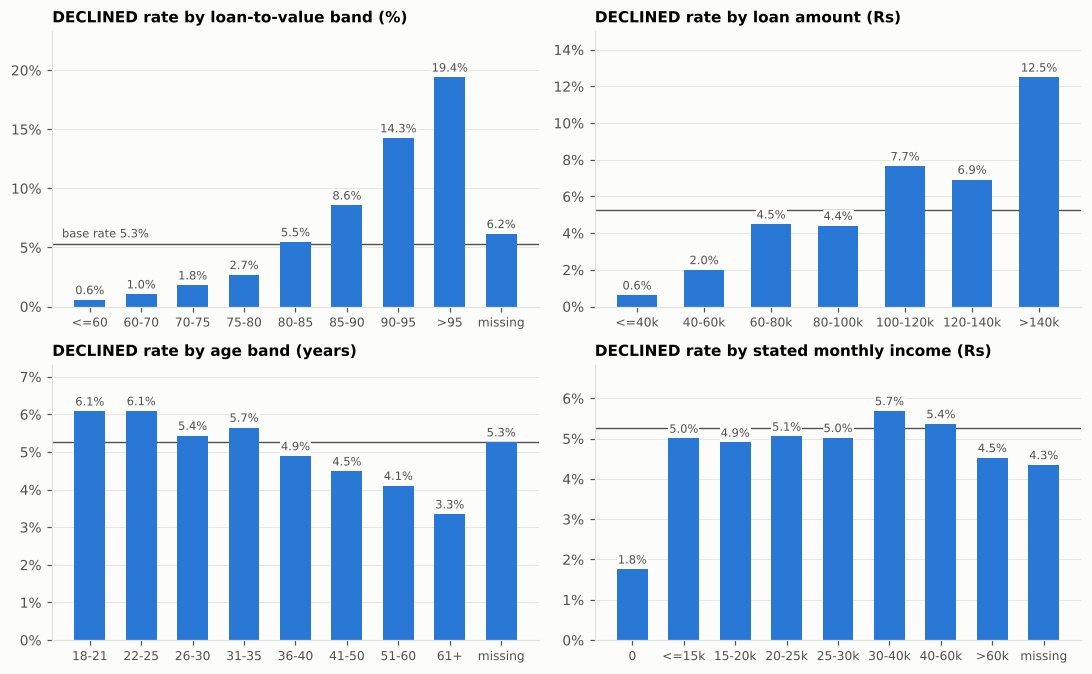

In [8]:
def rate_bars(ax, t, title, horizontal=False, label_n=False):
    x = ["missing" if str(i) == "nan" else str(i) for i in t.index]
    box = dict(facecolor=C["surface"], edgecolor="none", pad=0.6)        # labels sit on the surface, not on the reference line
    if horizontal:
        ax.axvline(base_rate, color=C["ink2"], lw=0.9, zorder=1)
        ax.barh(x, t["rate"], height=0.6, color=C["blue"], zorder=2); pct(ax, "x"); ax.grid(axis="y", visible=False)
        for i, (r, n) in enumerate(zip(t["rate"], t["n"])):
            ax.text(r + t["rate"].max() * 0.025, i, f"{r:.1%}" + (f"  (n={n:,})" if label_n else ""), va="center", fontsize=7.5, color=C["ink2"], bbox=box, zorder=3)
        ax.set_xlim(0, t["rate"].max() * (1.6 if label_n else 1.25)); ax.set_ylim(max(len(x), 7) - 0.4, -0.6)   # cap bar thickness for short lists
    else:
        ax.axhline(base_rate, color=C["ink2"], lw=0.9, zorder=1)
        ax.bar(x, t["rate"], width=0.6, color=C["blue"], zorder=2); pct(ax, "y"); ax.grid(axis="x", visible=False)
        for i, r in enumerate(t["rate"]):
            ax.text(i, r + t["rate"].max() * 0.025, f"{r:.1%}", ha="center", fontsize=7.5, color=C["ink2"], bbox=box, zorder=3)
        ax.set_ylim(0, t["rate"].max() * 1.2); ax.tick_params(axis="x", labelsize=8)
    ax.set_title(title)

fig, axs = plt.subplots(2, 2, figsize=(10, 6.2))
rate_bars(axs[0, 0], eda_tables["LTV"], "DECLINED rate by loan-to-value band (%)")
rate_bars(axs[0, 1], eda_tables["Loan_Amount"], "DECLINED rate by loan amount (Rs)")
rate_bars(axs[1, 0], eda_tables["Age"], "DECLINED rate by age band (years)")
rate_bars(axs[1, 1], eda_tables["Net_salary"], "DECLINED rate by stated monthly income (Rs)")
axs[0, 0].text(0.02, base_rate + 0.006, f"base rate {base_rate:.1%}", fontsize=7.5, color=C["ink2"], transform=axs[0, 0].get_yaxis_transform())
fig.tight_layout(); save(fig, "fig02_numeric")

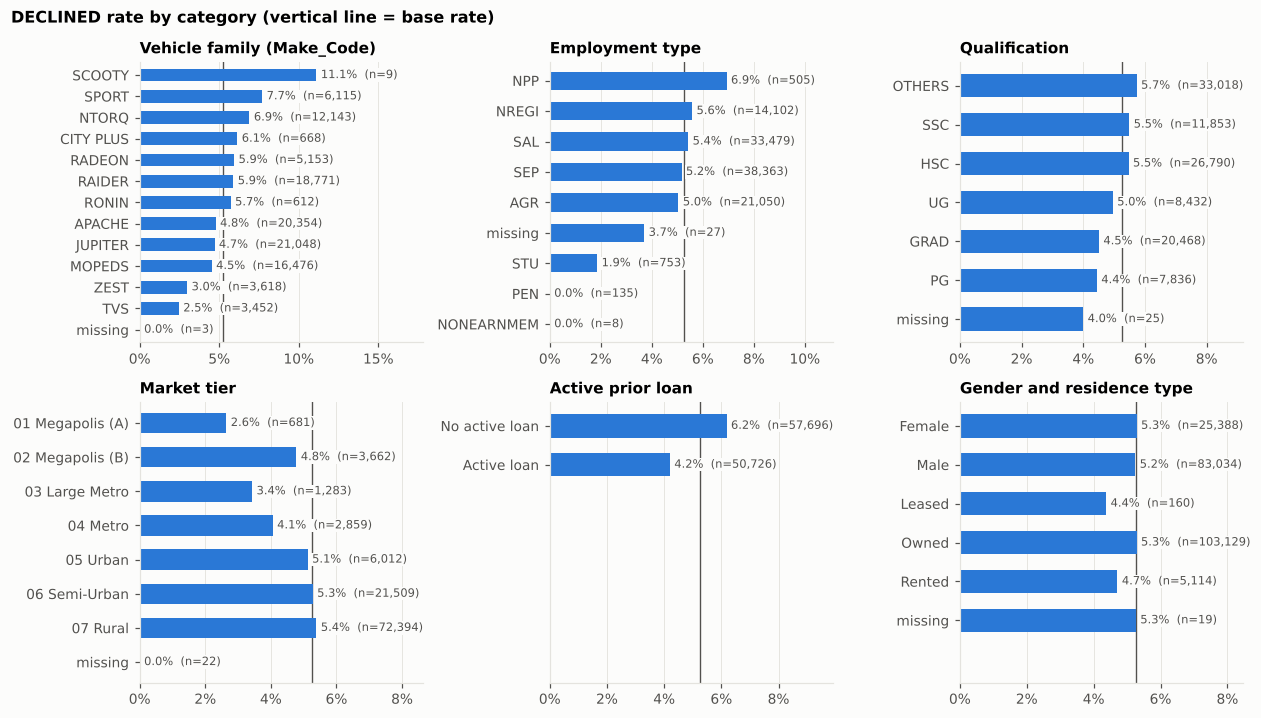

In [9]:
fig, axs = plt.subplots(2, 3, figsize=(11.5, 6.6))
order = lambda k: eda_tables[k].sort_values("rate", ascending=False)
rate_bars(axs[0, 0], order("Make_Code").rename(index=lambda s: str(s)), "Vehicle family (Make_Code)", True, True)
rate_bars(axs[0, 1], order("Employment_Type"), "Employment type", True, True)
rate_bars(axs[0, 2], order("Qualifications"), "Qualification", True, True)
rate_bars(axs[1, 0], eda_tables["Final_Tier"], "Market tier", True, True)
rate_bars(axs[1, 1], eda_tables["PAST_LOANS_ACTIVE"].rename(index={"NO_PAST_LOANS": "No active loan", "PAST_LOANS_ACTIVE": "Active loan"}), "Active prior loan", True, True)
rate_bars(axs[1, 2], pd.concat([eda_tables["Gender"], eda_tables["Resident_Type"].rename(index={"O": "Owned", "R": "Rented", "L": "Leased"})]), "Gender and residence type", True, True)
fig.suptitle("DECLINED rate by category (vertical line = base rate)", x=0.01, ha="left", fontsize=10.5, fontweight="bold")
fig.tight_layout(); save(fig, "fig03_categorical")

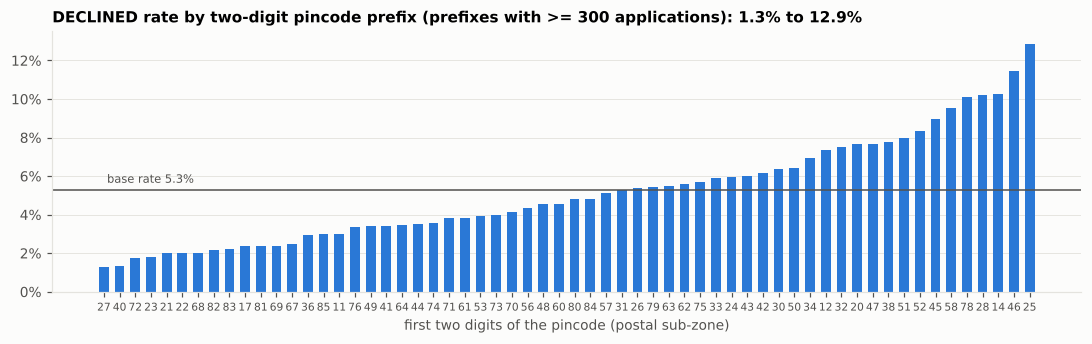

In [10]:
g = eda_tables["pin2"].query("n >= 300").sort_values("rate")
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(g.index, g["rate"], width=0.62, color=C["blue"]); pct(ax); ax.grid(axis="x", visible=False)
ax.axhline(base_rate, color=C["ink2"], lw=1); ax.text(0.2, base_rate + 0.004, f"base rate {base_rate:.1%}", fontsize=7.5, color=C["ink2"])
ax.set_title(f"DECLINED rate by two-digit pincode prefix (prefixes with >= 300 applications): {g['rate'].min():.1%} to {g['rate'].max():.1%}")
ax.set_xlabel("first two digits of the pincode (postal sub-zone)"); ax.tick_params(axis="x", labelsize=7)
fig.tight_layout(); save(fig, "fig04_geography")
RESULTS["eda_geo"] = {"pin2_min": float(g["rate"].min()), "pin2_max": float(g["rate"].max()), "pin2_groups": int(len(g))}

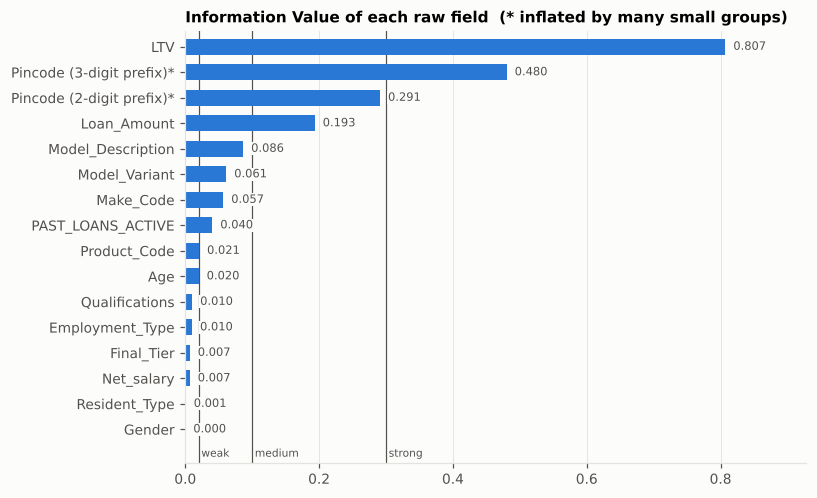

In [11]:
e["LTV_dec"] = pd.qcut(e["LTV_c"], 10, duplicates="drop"); e["Loan_dec"] = pd.qcut(e["Loan_Amount"], 10)
e["Age_dec"] = pd.qcut(e["Age_num"], 10, duplicates="drop"); e["Sal_dec"] = pd.qcut(e["Net_salary"], 10, duplicates="drop")
iv = pd.Series({
 "LTV": info_value("LTV_dec"), "Pincode (3-digit prefix)*": info_value("pin3"), "Pincode (2-digit prefix)*": info_value("pin2"),
 "Loan_Amount": info_value("Loan_dec"), "Model_Description": info_value("Model_Description"), "Make_Code": info_value("Make_Code"),
 "Model_Variant": info_value("Model_Variant"), "PAST_LOANS_ACTIVE": info_value("PAST_LOANS_ACTIVE"), "Age": info_value("Age_dec"),
 "Product_Code": info_value("Product_Code"), "Employment_Type": info_value("Employment_Type"), "Qualifications": info_value("Qualifications"),
 "Final_Tier": info_value("Final_Tier"), "Net_salary": info_value("Sal_dec"), "Resident_Type": info_value("Resident_Type"), "Gender": info_value("Gender"),
}).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for x, lbl in [(0.02, "weak"), (0.1, "medium"), (0.3, "strong")]:
    ax.axvline(x, color=C["ink2"], lw=0.8, zorder=1); ax.text(x + 0.004, -0.75, lbl, fontsize=7, color=C["ink2"], va="top")
ax.barh(iv.index, iv.values, height=0.62, color=C["blue"], zorder=2); ax.grid(axis="y", visible=False)
for i, v in enumerate(iv.values):
    ax.text(v + 0.012, i, f"{v:.3f}", va="center", fontsize=7.5, color=C["ink2"], zorder=3, bbox=dict(facecolor=C["surface"], edgecolor="none", pad=0.5))
ax.set_xlim(0, iv.max() * 1.15); ax.set_ylim(-1.3, len(iv) - 0.4)
ax.set_title("Information Value of each raw field  (* inflated by many small groups)")
fig.tight_layout(); save(fig, "fig05_information_value")
RESULTS["iv"] = iv.round(4).to_dict()

**What the exploration shows**

* **LTV dominates.** The decline rate climbs steadily with loan-to-value and jumps above 85%. It is the classic collateral-cushion variable in vehicle finance and the strongest single field by a wide margin.
* **Geography matters, city size does not.** Two-digit pincode prefixes differ roughly ten-fold in decline rate, while the market tier is nearly flat — *where* the applicant lives carries signal, the urban/rural label hardly any.
* **Larger loans and some vehicle families are riskier**, partly the same effect (premium motorcycles need bigger loans).
* **An active prior loan lowers the decline rate.** Counter-intuitive until one recalls that an existing loan means a verifiable repayment track record; new-to-credit applicants are harder to underwrite.
* **Self-reported income, residence type and gender carry almost no signal.** Income is heaped on round numbers and unverified; gender shows no difference at all.
* **No field looks like leakage**: nothing separates the classes suspiciously well, and `ID` (a row key) is excluded.

## 5. Cleaning and feature pipeline

`load_labelled()` removes the unlabelled row and exact duplicates. Everything else happens inside the scikit-learn `Pipeline`:

| Step | What it does | Why |
|---|---|---|
| `LoanFeatureBuilder` | type repair, impossible values → missing, text normalisation, explicit `MISSING` category, pincode hierarchy, LTV-based collateral features, vehicle attributes parsed from text | one implementation for train / test / chatbot |
| One-hot encoder | small categoricals; categories seen < 30 times **and unseen categories** go to an `infrequent` bucket | robust to new codes in the hidden test set |
| Target encoder | `Model_Description`, 2- and 3-digit pincode prefix → smoothed decline rate, **cross-fitted** so a row's own label never leaks into its feature; unseen category → global mean | handles high cardinality without leakage |
| LightGBM | gradient-boosted trees on the natural class distribution | non-linear effects, missing values, millisecond scoring |

In [12]:
X, y, load_log = F.load_labelled(DATA)
print(load_log)
fb = F.LoanFeatureBuilder().fit(X)
feats = fb.transform(X)
print("\nEngineered feature table:", feats.shape)
display(feats.head(3).T)
print("Model_Variant spellings after cleaning:", sorted(v for v in feats["Model_Variant"].unique() if "125" in v))
print("Descriptions still containing mis-decoded characters:", int(feats["Model_Description"].str.contains("â€").sum()),
      "| distinct descriptions:", feats["Model_Description"].nunique())
print("Missing values left for LightGBM to route:", feats.isna().sum()[lambda s: s > 0].to_dict())
RESULTS["load_log"] = load_log
RESULTS["features"] = {"n_engineered": int(feats.shape[1]), "categorical_onehot": F.CAT_LOW, "categorical_target_encoded": F.CAT_HIGH, "numeric": F.NUMERIC}

{'rows_read': 108423, 'rows_without_label_dropped': 1, 'exact_duplicates_dropped': 13, 'rows_used': 108409, 'declined': 5698, 'decline_rate': 0.052560211790533995}



Engineered feature table: (108409, 23)


,0,1,2
Qualifications,SSC,UG,GRAD
Employment_Type,AGR,SAL,NREGI
Resident_Type,O,O,R
Product_Code,MO,MC,SC
Make_Code,MOPEDS,APACHE,JUPITER
Model_Variant,XL 100 CC,RTR 200 CC,110 CC
PAST_LOANS_ACTIVE,PAST_LOANS_ACTIVE,PAST_LOANS_ACTIVE,PAST_LOANS_ACTIVE
Model_Description,TVS XL 100 HD ITS BSVI - WINNER EDITION,APACHE 200 4V 2CH - R MODE BSVI,JUPITER ZX BSVI - AOL - DRUM
pin2,50,50,50
pin3,502,503,500


Model_Variant spellings after cleaning: ['125 CC', '125 CC DISC', '125 CC DRUM']
Descriptions still containing mis-decoded characters: 0 | distinct descriptions: 88
Missing values left for LightGBM to route: {'Age': 17, 'LTV': 65, 'Net_salary': 23, 'tier_num': 22, 'vehicle_value': 65, 'down_payment': 65, 'price_vs_typical': 65, 'loan_to_annual_income': 647, 'engine_cc': 2}


## 6. Train / hold-out split

A **stratified** 80/20 split keeps the 5.3% DECLINED share identical in both parts — the first level at which the imbalance is handled. The 20% hold-out stands in for ABC Credit's hidden test set: it is scored once, in Section 12, after every choice (features, model, imbalance strategy, hyper-parameters, threshold) has been fixed using 5-fold stratified cross-validation on the 80%.

In [13]:
X_tr, X_ho, y_tr, y_ho = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
if FAST:
    X_tr, _, y_tr, _ = train_test_split(X_tr, y_tr, train_size=15000, stratify=y_tr, random_state=SEED)
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
split = pd.DataFrame({"rows": [len(y_tr), len(y_ho)], "declined": [int(y_tr.sum()), int(y_ho.sum())],
                      "declined_share": [y_tr.mean(), y_ho.mean()]}, index=["training (80%)", "hold-out (20%)"])
display(split.style.format({"declined_share": "{:.2%}", "rows": "{:,}", "declined": "{:,}"}))
print("declined per CV fold:", [int(y_tr.iloc[te].sum()) for _, te in cv5.split(X_tr, y_tr)])
RESULTS["split"] = {"train_rows": int(len(y_tr)), "train_declined": int(y_tr.sum()), "holdout_rows": int(len(y_ho)), "holdout_declined": int(y_ho.sum())}
pi = float(y_tr.mean())
def oof(pipe): return cross_val_predict(pipe, X_tr, y_tr, cv=cv5, method="predict_proba")[:, 1]
def rank_metrics(yt, p):
    return {"roc_auc": roc_auc_score(yt, p), "pr_auc": average_precision_score(yt, p), "log_loss": log_loss(yt, np.clip(p, 1e-6, 1 - 1e-6)),
            "brier": brier_score_loss(yt, p), "mean_p": float(np.mean(p))}

,rows,declined,declined_share
training (80%),"86,727","4,558",5.26%
hold-out (20%),"21,682","1,140",5.26%


declined per CV fold: [912, 912, 911, 911, 912]


## 7. Baselines and model comparison

"Above a benchmark" needs benchmarks. Two naive ones (approve everyone; rank by LTV alone) and five learned models are compared on **out-of-fold** predictions. Because of the imbalance the comparison uses ranking metrics that do not depend on a cut-off — ROC-AUC and PR-AUC (whose random baseline is the 5.3% base rate) — plus log loss and Brier score for probability quality.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

def sk_pipe(model, scale=False):
    steps = [("features", F.LoanFeatureBuilder()), ("encode", F.make_encoder()), ("impute", SimpleImputer(strategy="median"))]
    if scale: steps.append(("scale", StandardScaler()))
    return Pipeline(steps + [("model", model)])
candidates = {
 "Logistic regression": sk_pipe(LogisticRegression(C=0.5, max_iter=2000), scale=True),
 "Decision tree (depth 6)": sk_pipe(DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, random_state=SEED)),
 "Random forest (200 trees)": sk_pipe(RandomForestClassifier(200 if not FAST else 40, min_samples_leaf=50, max_features=0.3, n_jobs=2, random_state=SEED)),
 "HistGradientBoosting": Pipeline([("features", F.LoanFeatureBuilder()), ("encode", F.make_encoder()),
                                   ("model", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=100, random_state=SEED))]),
 "LightGBM": F.build_pipeline(n_estimators=900, learning_rate=0.02, num_leaves=7),
}
ltv_tr = F.basic_clean(X_tr)["LTV"].fillna(0).values
rows, oof_p = [], {}
rows.append({"model": "Always approve (constant score)", **rank_metrics(y_tr, np.full(len(y_tr), pi)), "seconds": 0.0})
rows.append({"model": "Rank by LTV alone", "roc_auc": roc_auc_score(y_tr, ltv_tr), "pr_auc": average_precision_score(y_tr, ltv_tr)})
for name, pipe in candidates.items():
    t0 = time.time(); oof_p[name] = oof(pipe)
    rows.append({"model": name, **rank_metrics(y_tr, oof_p[name]), "seconds": time.time() - t0}); print(name, "done")
cmp = pd.DataFrame(rows).set_index("model")
display(cmp.style.format("{:.4f}", na_rep="-").format({"seconds": "{:.0f}"}, na_rep="-"))
RESULTS["model_comparison"] = cmp.round(5).reset_index().to_dict("records")

Logistic regression done


Decision tree (depth 6) done


Random forest (200 trees) done


HistGradientBoosting done


LightGBM done


,roc_auc,pr_auc,log_loss,brier,mean_p,seconds
model,,,,,,
Always approve (constant score),0.500000,0.052556,0.205973,0.049794,0.052556,0
Rank by LTV alone,0.734024,0.124625,-,-,-,-
Logistic regression,0.775986,0.167942,0.180828,0.046713,0.052547,13
Decision tree (depth 6),0.755824,0.145551,0.184934,0.047374,0.052669,14
Random forest (200 trees),0.779598,0.172027,0.179371,0.046537,0.052439,100
HistGradientBoosting,0.781786,0.175410,0.178734,0.046449,0.052394,20
LightGBM,0.784466,0.180422,0.178033,0.046324,0.052460,23


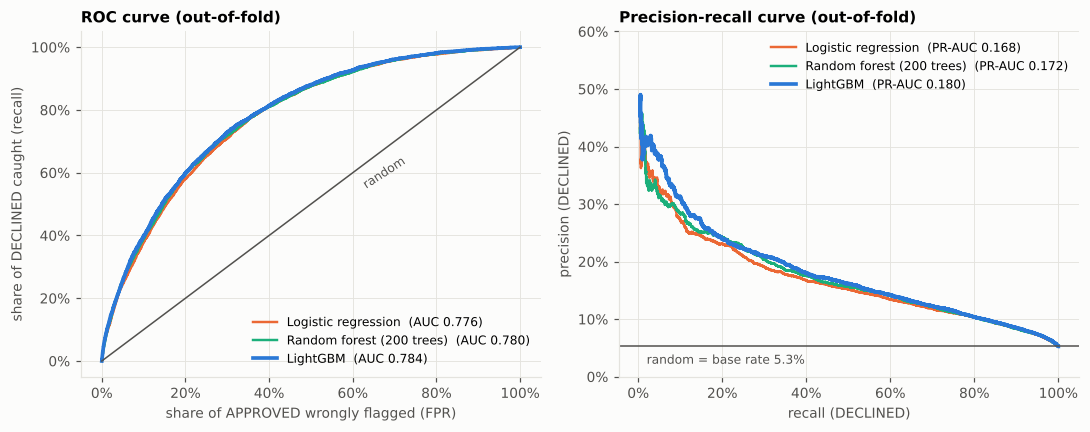

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
styles = {"Logistic regression": (C["orange"], 1.6), "Random forest (200 trees)": (C["aqua"], 1.6), "LightGBM": (C["blue"], 2.4)}
for name, (col, lw) in styles.items():
    fpr, tpr, _ = roc_curve(y_tr, oof_p[name]); prec, rec, _ = precision_recall_curve(y_tr, oof_p[name])
    axs[0].plot(fpr, tpr, color=col, lw=lw, label=f"{name}  (AUC {roc_auc_score(y_tr, oof_p[name]):.3f})")
    ok = rec > 0.004                                              # the first handful of cases make the left edge jump
    axs[1].plot(rec[ok], prec[ok], color=col, lw=lw, label=f"{name}  (PR-AUC {average_precision_score(y_tr, oof_p[name]):.3f})")
axs[0].plot([0, 1], [0, 1], color=C["ink2"], lw=1); axs[0].text(0.62, 0.55, "random", fontsize=8, color=C["ink2"], rotation=33)
axs[0].set(title="ROC curve (out-of-fold)", xlabel="share of APPROVED wrongly flagged (FPR)", ylabel="share of DECLINED caught (recall)")
axs[1].axhline(pi, color=C["ink2"], lw=1); axs[1].text(0.02, pi - 0.03, f"random = base rate {pi:.1%}", fontsize=8, color=C["ink2"])
axs[1].set(title="Precision-recall curve (out-of-fold)", xlabel="recall (DECLINED)", ylabel="precision (DECLINED)", ylim=(0, 0.6))
for a in axs: a.legend(fontsize=8, loc="lower right" if a is axs[0] else "upper right"); pct(a, "x"); pct(a, "y")
fig.tight_layout(); save(fig, "fig06_model_comparison")

**Reading the comparison.** Every learned model beats the naive benchmarks by a wide margin (PR-AUC roughly 3× the random baseline). LightGBM is best on every metric; the margin over logistic regression is modest, which is typical when one variable (LTV) dominates. The ceiling is set by information, not algorithms: underwriters saw bureau reports and field checks that are not in these 15 fields. LightGBM is carried forward because it ranks best, handles missing values and unseen categories natively, and scores a row in milliseconds.

## 8. Handling class imbalance

Only 5.3% of applications are DECLINED. Two things go wrong if this is ignored: **accuracy** rewards approving everyone (94.7%), and the **default 0.5 cut-off** flags almost nobody. The imbalance is therefore handled explicitly at five levels:

| Level | What is done | Where |
|---|---|---|
| 1 Splitting | stratified hold-out and stratified 5-fold CV — every fold has the same 5.3% | Section 6 |
| 2 Metrics | PR-AUC, recall / precision / F1 **on the DECLINED class**, MCC, balanced accuracy; accuracy only next to the 94.7% baseline | Sections 7, 12 |
| 3 Training | seven strategies compared **inside cross-validation** (resampling applied to training folds only, via an `imblearn` pipeline — never to validation or test data) | this section |
| 4 Probabilities | the prior shift introduced by weighting / resampling is measured and corrected; calibration is checked | this section, Section 11 |
| 5 Decision | a cost-sensitive threshold far below 0.5, chosen from the business cost of the two errors | Section 11 |

The experiment asks one question of each strategy: *does it rank applicants better, or does it only move the cut-off?*

In [16]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.metrics import precision_score, recall_score
from lightgbm import LGBMClassifier

BASE = dict(n_estimators=900, learning_rate=0.02, num_leaves=7)
ratio = (1 - pi) / pi                                           # ~18 approvals per decline
lgbm = lambda **k: LGBMClassifier(**{**F.LGBM_DEFAULTS, **BASE, **k})
def with_sampler(sampler):                                      # sampler sits AFTER encoding, INSIDE the CV pipeline
    return ImbPipeline([("features", F.LoanFeatureBuilder()), ("encode", F.make_encoder()),
                        ("impute", SimpleImputer(strategy="median")), ("sample", sampler), ("model", lgbm())])
cat_cols = F.CAT_LOW + F.CAT_HIGH
def smote_nc():                                                 # SMOTE-NC needs the raw categorical columns
    imp = ColumnTransformer([("c", "passthrough", cat_cols), ("n", SimpleImputer(strategy="median"), F.NUMERIC)],
                            verbose_feature_names_out=False).set_output(transform="pandas")
    return ImbPipeline([("features", F.LoanFeatureBuilder()), ("impute", imp),
                        ("sample", SMOTENC(categorical_features=cat_cols, random_state=SEED)),
                        ("encode", F.make_encoder()), ("model", lgbm())])
strategies = {   # name: (pipeline, factor by which the training odds of DECLINED were inflated)
 "None: natural 5.3% + threshold": (F.build_pipeline(**BASE), 1.0),
 "Class weight 'balanced' (x18)": (F.build_pipeline(**BASE, scale_pos_weight=ratio), ratio),
 "Moderate class weight (x4.2)": (F.build_pipeline(**BASE, scale_pos_weight=np.sqrt(ratio)), np.sqrt(ratio)),
 "Random oversampling 1:1": (with_sampler(RandomOverSampler(random_state=SEED)), ratio),
 "Random undersampling 1:1": (with_sampler(RandomUnderSampler(random_state=SEED)), ratio),
 "SMOTE-NC 1:1 (synthetic declines)": (smote_nc(), ratio),
 "Balanced bagging (10 x undersample)": (ImbPipeline([("features", F.LoanFeatureBuilder()), ("encode", F.make_encoder()),
      ("model", BalancedBaggingClassifier(estimator=lgbm(n_jobs=1, n_estimators=400, learning_rate=0.04), n_estimators=10, random_state=SEED, n_jobs=2))]), ratio),
}
def prior_correct(p, w):                                        # Elkan (2001) / Saerens et al. (2002): odds_true = odds_model / w
    o = p / (1 - p) / w
    return o / (1 + o)
imb_rows, imb_oof = [], {}
for name, (pipe, w) in strategies.items():
    t0 = time.time(); p = oof(pipe); pc = prior_correct(p, w); imb_oof[name] = p
    top10 = p >= np.quantile(p, 0.90)
    imb_rows.append({"strategy": name, "roc_auc": roc_auc_score(y_tr, p), "pr_auc": average_precision_score(y_tr, p),
        "recall_if_top10pct_declined": recall_score(y_tr, top10),
        "mean_predicted_p": p.mean(), "brier_raw": brier_score_loss(y_tr, p),
        "recall_at_0.5": recall_score(y_tr, p >= 0.5), "precision_at_0.5": precision_score(y_tr, p >= 0.5, zero_division=0),
        "share_declined_at_0.5": (p >= 0.5).mean(),
        "mean_p_after_prior_correction": pc.mean(), "brier_after_correction": brier_score_loss(y_tr, pc), "seconds": time.time() - t0})
    print(f"{name:38s} ROC-AUC {imb_rows[-1]['roc_auc']:.4f}  PR-AUC {imb_rows[-1]['pr_auc']:.4f}  mean p {p.mean():.3f}")
imb = pd.DataFrame(imb_rows).set_index("strategy")
imb.to_csv("outputs/imbalance_experiment.csv")
display(imb.style.format("{:.4f}").format({"seconds": "{:.0f}"}))
RESULTS["imbalance"] = imb.round(5).reset_index().to_dict("records")

None: natural 5.3% + threshold         ROC-AUC 0.7845  PR-AUC 0.1804  mean p 0.052


Class weight 'balanced' (x18)          ROC-AUC 0.7836  PR-AUC 0.1768  mean p 0.373


Moderate class weight (x4.2)           ROC-AUC 0.7844  PR-AUC 0.1800  mean p 0.164


Random oversampling 1:1                ROC-AUC 0.7831  PR-AUC 0.1768  mean p 0.375


Random undersampling 1:1               ROC-AUC 0.7805  PR-AUC 0.1706  mean p 0.389


SMOTE-NC 1:1 (synthetic declines)      ROC-AUC 0.7548  PR-AUC 0.1499  mean p 0.144


Balanced bagging (10 x undersample)    ROC-AUC 0.7843  PR-AUC 0.1762  mean p 0.380


,roc_auc,pr_auc,recall_if_top10pct_declined,mean_predicted_p,brier_raw,recall_at_0.5,precision_at_0.5,share_declined_at_0.5,mean_p_after_prior_correction,brier_after_correction,seconds
strategy,,,,,,,,,,,
None: natural 5.3% + threshold,0.784466,0.180422,0.364634,0.052460,0.046324,0.001097,0.416667,0.000138,0.052460,0.046324,24
Class weight 'balanced' (x18),0.783615,0.176780,0.361343,0.372942,0.185864,0.742431,0.115787,0.336988,0.049016,0.046443,23
Moderate class weight (x4.2),0.784440,0.179964,0.365072,0.163569,0.066753,0.171566,0.254640,0.035410,0.051186,0.046340,23
Random oversampling 1:1,0.783101,0.176761,0.362001,0.375202,0.185932,0.738262,0.115915,0.334729,0.049183,0.046447,35
Random undersampling 1:1,0.780453,0.170647,0.346863,0.388992,0.197127,0.748355,0.112522,0.349534,0.054113,0.046607,16
SMOTE-NC 1:1 (synthetic declines),0.754823,0.149914,0.326459,0.144108,0.064268,0.160158,0.227556,0.036990,0.011854,0.050056,85
Balanced bagging (10 x undersample),0.784320,0.176198,0.365072,0.379550,0.188200,0.741334,0.115739,0.336631,0.050263,0.046408,27


,weighted model at the default 0.5,natural model at threshold 0.053
share of applicants declined,33.7%,33.7%
recall (DECLINED),74.2%,74.3%
precision (DECLINED),11.6%,11.6%


Theory (Elkan 2001): weighting DECLINED by w and cutting at 0.5 is the same rule as cutting a calibrated probability at 1/(1+w) = 0.053


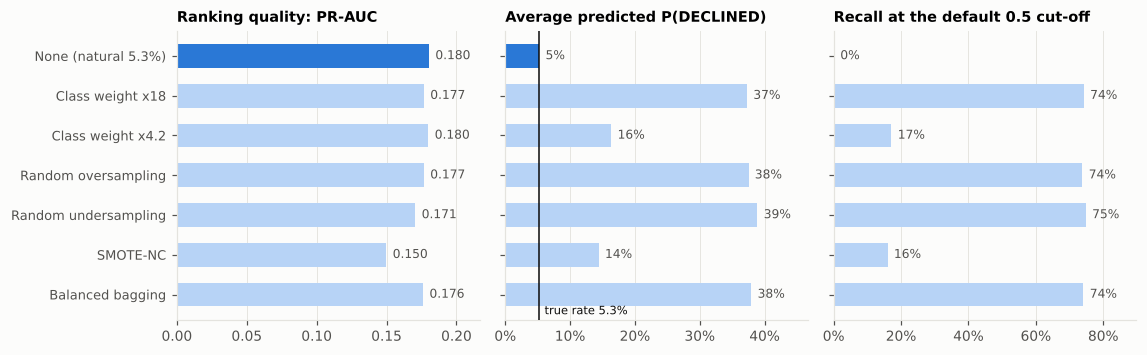

In [17]:
# Does class weighting find risky applicants that the plain model misses, or does it only move the cut-off?
p_nat, p_w = imb_oof["None: natural 5.3% + threshold"], imb_oof["Class weight 'balanced' (x18)"]
share_w = (p_w >= 0.5).mean()
t_equiv = np.quantile(p_nat, 1 - share_w)                       # natural-model threshold that declines the same share
eq = pd.DataFrame({
 "weighted model at the default 0.5": [share_w, recall_score(y_tr, p_w >= 0.5), precision_score(y_tr, p_w >= 0.5)],
 f"natural model at threshold {t_equiv:.3f}": [(p_nat >= t_equiv).mean(), recall_score(y_tr, p_nat >= t_equiv), precision_score(y_tr, p_nat >= t_equiv)],
}, index=["share of applicants declined", "recall (DECLINED)", "precision (DECLINED)"])
display(eq.style.format("{:.1%}"))
print(f"Theory (Elkan 2001): weighting DECLINED by w and cutting at 0.5 is the same rule as cutting a calibrated probability at 1/(1+w) = {1/(1+ratio):.3f}")
RESULTS["imbalance_equivalence"] = {"share_declined": float(share_w), "t_equiv": float(t_equiv),
    "weighted": {"recall": float(eq.iloc[1, 0]), "precision": float(eq.iloc[2, 0])}, "natural": {"recall": float(eq.iloc[1, 1]), "precision": float(eq.iloc[2, 1])}}

short = ["None (natural 5.3%)", "Class weight x18", "Class weight x4.2", "Random oversampling", "Random undersampling", "SMOTE-NC", "Balanced bagging"]
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.3), sharey=True)
for ax, col, title, fmt in [(axs[0], "pr_auc", "Ranking quality: PR-AUC", "{:.3f}"),
                            (axs[1], "mean_predicted_p", "Average predicted P(DECLINED)", "{:.0%}"),
                            (axs[2], "recall_at_0.5", "Recall at the default 0.5 cut-off", "{:.0%}")]:
    ax.barh(short, imb[col], height=0.6, color=[C["blue"]] + [C["pale"]] * 6, zorder=2); ax.grid(axis="y", visible=False)
    for i, v in enumerate(imb[col]): ax.text(v + imb[col].max() * 0.025, i, fmt.format(v), va="center", fontsize=8, color=C["ink2"], zorder=3)
    ax.set_title(title, fontsize=9.5); ax.set_xlim(0, imb[col].max() * 1.2)
axs[0].invert_yaxis(); axs[0].tick_params(axis="y", labelsize=8.5)
axs[1].axvline(pi, color=C["ink"], lw=1, zorder=3); axs[1].text(pi + 0.008, 6.42, f"true rate {pi:.1%}", fontsize=7.5, color=C["ink"], va="center"); pct(axs[1], "x"); pct(axs[2], "x")
fig.tight_layout(); save(fig, "fig07_imbalance")

**What the experiment shows — and the decision**

* **No training-time correction improves the ranking.** ROC-AUC and PR-AUC of the class-weighted, oversampled and bagged models are within noise of the uncorrected model; undersampling is slightly worse (it discards 94% of the approvals) and SMOTE-NC clearly worse (interpolated "applicants" between mixed categorical records are not realistic).
* **What the corrections do change is the probability scale.** Balanced weights or 1:1 resampling push the average predicted P(DECLINED) from the true 5% to about 37%. That is why they "achieve" ~74% recall at the default 0.5 cut-off — while declining a third of all applicants at ~12% precision.
* **The same operating point is available without them.** Cutting the natural-prior model at the threshold that declines the same share of applicants gives the same recall and precision (table above). Weighting DECLINED by *w* and cutting at 0.5 is mathematically the rule "decline if p ≥ 1/(1+w)" on a calibrated model.
* **After prior correction** (dividing the odds by the weight) the weighted and resampled models are calibrated again and indistinguishable from the natural model — confirming they carry no extra information.

**Decision.** Train on the natural class distribution (probabilities stay calibrated and auditable), and correct for the imbalance where it actually bites: in the **decision threshold**, set cost-sensitively in Section 11, and in the **metrics**. This is cost-sensitive learning applied at the decision stage; it is equivalent to class-weighted training but keeps one honest probability per applicant. This replicates on ABC Credit's own data the published findings of van den Goorbergh et al. (2022), Carriero et al. (2025) and Elor & Averbuch-Elor (2022).

## 9. Selecting the minimal set of questions

Every question costs applicant time and collects more personal data, so the unit of selection is the **question**, not the column: one answer can feed several model features (the vehicle model gives make, variant, product and engine size; the pincode gives zone, district and market tier; price and loan give LTV). Greedy **forward selection over questions** adds, at each step, the question that most improves 5-fold cross-validated PR-AUC.

Fields that are never candidates: `ID` (row key), `Gender` (no signal, fairness risk), and the derivable `Final_Tier`, `Make_Code`, `Model_Variant`, `Product_Code` (obtained from master data, not asked).

In [18]:
QUESTIONS = {   # question -> model features it produces
 "price_and_loan":  ["LTV", "Loan_Amount", "vehicle_value", "down_payment"],
 "pincode":         ["pin2", "pin3", "pin_zone", "tier_num"],
 "vehicle_model":   ["Model_Description", "Make_Code", "Model_Variant", "Product_Code", "engine_cc", "is_disc"],
 "active_loans":    ["PAST_LOANS_ACTIVE"],
 "employment_type": ["Employment_Type"],
 "age":             ["Age"],
 "qualification":   ["Qualifications"],
 "net_salary":      ["Net_salary", "salary_is_zero"],
 "residence_type":  ["Resident_Type"],
}
DERIVED = {"price_vs_typical": {"vehicle_model", "price_and_loan"}, "loan_to_annual_income": {"price_and_loan", "net_salary"}}
def features_for(questions):
    return [c for q in questions for c in QUESTIONS[q]] + [d for d, need in DERIVED.items() if need <= set(questions)]
def cv_score(questions):
    r = cross_validate(F.build_pipeline(keep=features_for(questions), n_estimators=400, learning_rate=0.04, num_leaves=7),
                       X_tr, y_tr, cv=cv5, scoring=["average_precision", "roc_auc"])
    return r["test_average_precision"].mean(), r["test_average_precision"].std(), r["test_roc_auc"].mean()
selected, remaining, path = [], list(QUESTIONS), []
t0 = time.time()
while remaining:
    trials = {q: cv_score(selected + [q]) for q in remaining}
    best = max(trials, key=lambda q: trials[q][0])
    selected.append(best); remaining.remove(best)
    path.append({"step": len(selected), "question_added": best, "cv_pr_auc": trials[best][0], "fold_sd": trials[best][1], "cv_roc_auc": trials[best][2]})
    print(f"step {len(selected)}: + {best:16s} PR-AUC {trials[best][0]:.4f}  ROC-AUC {trials[best][2]:.4f}")
path = pd.DataFrame(path); path["gain"] = path["cv_pr_auc"].diff()
print(f"({time.time() - t0:.0f}s)")

step 1: + price_and_loan   PR-AUC 0.1366  ROC-AUC 0.7402


step 2: + pincode          PR-AUC 0.1634  ROC-AUC 0.7689


step 3: + active_loans     PR-AUC 0.1703  ROC-AUC 0.7734


step 4: + vehicle_model    PR-AUC 0.1759  ROC-AUC 0.7809


step 5: + employment_type  PR-AUC 0.1781  ROC-AUC 0.7816


step 6: + age              PR-AUC 0.1790  ROC-AUC 0.7838


step 7: + qualification    PR-AUC 0.1809  ROC-AUC 0.7841


step 8: + net_salary       PR-AUC 0.1811  ROC-AUC 0.7845


step 9: + residence_type   PR-AUC 0.1807  ROC-AUC 0.7842
(689s)


,step,question_added,cv_pr_auc,fold_sd,cv_roc_auc,gain,decision
0,1,price_and_loan,0.1366,0.0037,0.7402,-,keep
1,2,pincode,0.1634,0.0071,0.7689,+0.0268,keep
2,3,active_loans,0.1703,0.0069,0.7734,+0.0069,keep
3,4,vehicle_model,0.1759,0.0057,0.7809,+0.0056,keep
4,5,employment_type,0.1781,0.0058,0.7816,+0.0022,keep
5,6,age,0.1790,0.0075,0.7838,+0.0009,keep
6,7,qualification,0.1809,0.0065,0.7841,+0.0019,keep
7,8,net_salary,0.1811,0.0075,0.7845,+0.0001,keep
8,9,residence_type,0.1807,0.0075,0.7842,-0.0003,drop


Questions kept   : ['price_and_loan', 'pincode', 'vehicle_model', 'active_loans', 'employment_type', 'age', 'qualification', 'net_salary']
Questions dropped: ['residence_type'] (plus Gender and ID, never candidates)
Model features   : 22 ['LTV', 'Loan_Amount', 'vehicle_value', 'down_payment', 'pin2', 'pin3', 'pin_zone', 'tier_num', 'Model_Description', 'Make_Code', 'Model_Variant', 'Product_Code', 'engine_cc', 'is_disc', 'PAST_LOANS_ACTIVE', 'Employment_Type', 'Age', 'Qualifications', 'Net_salary', 'salary_is_zero', 'price_vs_typical', 'loan_to_annual_income']


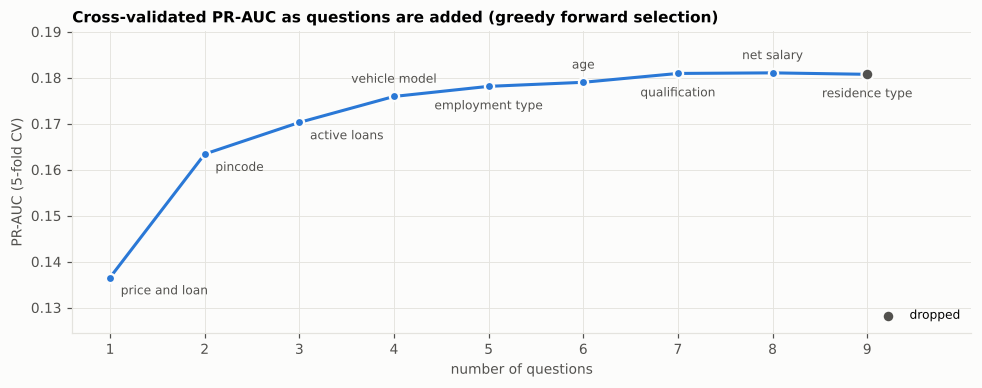

In [19]:
best_step = int(path["cv_pr_auc"].idxmax())
statistical = path["question_added"].iloc[: best_step + 1].tolist()        # questions that add cross-validated signal
MANDATED = ["age", "employment_type", "net_salary"]   # RBI (Digital Lending) Directions 2025: age, occupation and income must be captured
final_questions = [q for q in QUESTIONS if q in set(statistical) | set(MANDATED)]
dropped = [q for q in QUESTIONS if q not in final_questions]
KEEP = features_for(final_questions)
path["decision"] = ["keep" if q in final_questions else "drop" for q in path["question_added"]]
display(path.style.format({"cv_pr_auc": "{:.4f}", "fold_sd": "{:.4f}", "cv_roc_auc": "{:.4f}", "gain": "{:+.4f}"}, na_rep="-"))
print("Questions kept   :", final_questions)
print("Questions dropped:", dropped, "(plus Gender and ID, never candidates)")
print("Model features   :", len(KEEP), KEEP)

fig, ax = plt.subplots(figsize=(9, 3.6))
keep_mask = path["decision"].eq("keep")
ax.plot(path["step"], path["cv_pr_auc"], color=C["blue"], marker="o", ms=6, mec=C["surface"], mew=1.5)
ax.scatter(path.loc[~keep_mask, "step"], path.loc[~keep_mask, "cv_pr_auc"], s=60, color=C["ink2"], zorder=3, edgecolor=C["surface"], linewidth=1.5, label="dropped")
for _, r in path.iterrows():                                   # steep part: label to the lower right; flat part: alternate above / below
    steep = r["step"] <= 3
    off, ha = ((7, -11), "left") if steep else ((0, 9) if r["step"] % 2 == 0 else (0, -15), "center")
    ax.annotate(r["question_added"].replace("_", " "), (r["step"], r["cv_pr_auc"]), textcoords="offset points", xytext=off, ha=ha, fontsize=8, color=C["ink2"])
ax.set(title="Cross-validated PR-AUC as questions are added (greedy forward selection)", xlabel="number of questions", ylabel="PR-AUC (5-fold CV)")
ax.set_ylim(path["cv_pr_auc"].min() - 0.012, path["cv_pr_auc"].max() + 0.009); ax.set_xlim(0.6, len(path) + 1.1); ax.set_xticks(path["step"]); ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); save(fig, "fig08_question_selection")
RESULTS["question_selection"] = {"path": path.round(5).to_dict("records"), "final_questions": final_questions, "dropped": dropped,
                                 "statistical": statistical, "mandated": MANDATED, "model_features": KEEP}

**Result.** Performance rises steeply over the first four questions (price and loan → LTV, pincode, active loans, vehicle model) and then flattens: employment, age and education each add a little, income adds essentially nothing and residence type slightly *reduces* cross-validated PR-AUC.

* **Kept on statistical grounds:** the questions up to the peak of the curve.
* **Kept on regulatory grounds:** age, occupation and income are the minimum economic profile RBI's Digital Lending Directions (2025) require a lender to capture before extending a loan, and the brief itself lists "self-reported finances" among the information to collect. Income is therefore asked even though it barely moves the model; including it does not hurt.
* **Dropped:** residence type (no signal, lowers CV score) and gender (no signal, fairness risk). `Final_Tier`, make, variant and product are derived, never asked.

## 10. Hyper-parameter tuning

A randomised search over LightGBM's main capacity and regularisation controls, scored by 3-fold stratified CV on the training split with **average precision (PR-AUC)** — an imbalance-appropriate metric — on the selected feature set.

In [20]:
space = {"model__num_leaves": [7, 15, 31], "model__min_child_samples": [50, 100, 200, 400], "model__learning_rate": [0.02, 0.03, 0.05],
         "model__n_estimators": [400, 700, 1000], "model__colsample_bytree": [0.5, 0.7, 0.9], "model__reg_lambda": [0.0, 1.0, 5.0]}
search = RandomizedSearchCV(F.build_pipeline(keep=KEEP), space, n_iter=12 if not FAST else 2, scoring="average_precision", random_state=SEED,
                            cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=1, refit=False)
t0 = time.time(); search.fit(X_tr, y_tr); print(f"search took {time.time() - t0:.0f}s")
tune = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")[[c for c in search.cv_results_ if c.startswith("param_")] + ["mean_test_score", "std_test_score"]]
tune.columns = [c.replace("param_model__", "") for c in tune.columns]
display(tune.style.format({"mean_test_score": "{:.4f}", "std_test_score": "{:.4f}"}))
BEST = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print("chosen:", BEST)
RESULTS["tuning"] = {"best_params": BEST, "table": tune.round(5).to_dict("records")}

search took 221s


,reg_lambda,num_leaves,n_estimators,min_child_samples,learning_rate,colsample_bytree,mean_test_score,std_test_score
0,5.000000,7,700,50,0.030000,0.900000,0.1767,0.0040
7,1.000000,7,700,200,0.050000,0.500000,0.1767,0.0044
2,0.000000,7,1000,400,0.030000,0.900000,0.1764,0.0044
11,0.000000,15,400,50,0.050000,0.900000,0.1751,0.0027
1,1.000000,31,700,200,0.020000,0.500000,0.1735,0.0035
10,5.000000,15,700,50,0.050000,0.700000,0.1715,0.0041
5,1.000000,15,1000,400,0.030000,0.700000,0.1713,0.0039
6,1.000000,31,400,200,0.050000,0.500000,0.1686,0.0038
3,5.000000,31,1000,100,0.030000,0.700000,0.1663,0.0035
4,5.000000,15,1000,400,0.050000,0.700000,0.1647,0.0030


chosen: {'reg_lambda': 5.0, 'num_leaves': 7, 'n_estimators': 700, 'min_child_samples': 50, 'learning_rate': 0.03, 'colsample_bytree': 0.9}


## 11. Calibration and decision threshold

**Calibration first.** The threshold rule below is only valid if a predicted 0.20 really means "about 20% of such applications were declined". Out-of-fold probabilities of the tuned model are checked with a reliability table, the calibration slope and intercept, and the expected calibration error.

**Then the threshold — where the imbalance is corrected.** For a calibrated probability *p*, approving costs *p · c_FN* in expectation (a should-decline applicant approved) and declining costs *(1 − p) · c_FP* (a good customer lost). Declining is the cheaper action when

$$p \;\ge\; t^{*} = \frac{c_{FP}}{c_{FP}+c_{FN}} = \frac{1}{1+R}, \qquad R = c_{FN}/c_{FP}.$$

The cost ratio *R* is a business input. Illustrative unit economics for a two-wheeler NBFC (assumptions, documented in the report): a wrongly approved bad loan loses roughly Rs 45–55 thousand (most of a ~Rs 90 thousand exposure at 40–60% loss severity plus collection cost), a wrongly declined good customer forgoes roughly Rs 6–9 thousand of net margin and fees — a ratio of about **5 to 10, central value 7**. The threshold is fixed here, on out-of-fold training predictions, and never re-tuned on the hold-out.

In [21]:
tuned = lambda: F.build_pipeline(keep=KEEP, **BEST)
p_oof = oof(tuned())
oof_rank = rank_metrics(y_tr, p_oof)
logit = np.log(p_oof / (1 - p_oof)).reshape(-1, 1)
cal_fit = LogisticRegression(C=1e6, max_iter=1000).fit(logit, y_tr)
bins = pd.qcut(p_oof, 10, labels=False, duplicates="drop")
rel = pd.DataFrame({"p": p_oof, "y": y_tr.values, "bin": bins}).groupby("bin").agg(n=("y", "size"), mean_predicted=("p", "mean"), observed_rate=("y", "mean"))
ece = float((rel["n"] / rel["n"].sum() * (rel["mean_predicted"] - rel["observed_rate"]).abs()).sum())
calib = {"slope": float(cal_fit.coef_[0, 0]), "intercept": float(cal_fit.intercept_[0]), "ece": ece, "mean_predicted": float(p_oof.mean()), "observed": float(y_tr.mean())}
display(rel.style.format({"mean_predicted": "{:.3f}", "observed_rate": "{:.3f}"}))
print({k: round(v, 4) for k, v in oof_rank.items()}); print({k: round(v, 4) for k, v in calib.items()})
needs_recalibration = abs(calib["slope"] - 1) > 0.10 or ece > 0.01
print("Recalibration needed:", needs_recalibration, "-> probabilities are used as they are" if not needs_recalibration else "")
RESULTS["oof"] = {**oof_rank, "calibration": calib, "needs_recalibration": bool(needs_recalibration)}

,n,mean_predicted,observed_rate
bin,,,
0,8673,0.004,0.004
1,8673,0.007,0.007
2,8672,0.012,0.010
3,8673,0.018,0.020
4,8673,0.025,0.027
5,8672,0.036,0.037
6,8673,0.051,0.051
7,8672,0.071,0.072
8,8673,0.104,0.107


{'roc_auc': 0.7847, 'pr_auc': 0.179, 'log_loss': 0.1781, 'brier': 0.0463, 'mean_p': 0.0525}
{'slope': 0.9813, 'intercept': -0.043, 'ece': 0.0014, 'mean_predicted': 0.0525, 'observed': 0.0526}
Recalibration needed: False -> probabilities are used as they are


In [22]:
def at_threshold(yt, p, t):
    yt = np.asarray(yt); d = p >= t
    tp, fp, fn, tn = int((d & (yt == 1)).sum()), int((d & (yt == 0)).sum()), int((~d & (yt == 1)).sum()), int((~d & (yt == 0)).sum())
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return {"threshold": float(t), "share_declined": float(d.mean()), "accuracy": (tp + tn) / len(yt),
            "precision_declined": prec, "recall_declined": rec, "f1_declined": 2 * prec * rec / max(prec + rec, 1e-12),
            "precision_approved": tn / max(tn + fn, 1), "recall_approved": tn / max(tn + fp, 1),
            "balanced_accuracy": balanced_accuracy_score(yt, d), "mcc": matthews_corrcoef(yt, d), "tp": tp, "fp": fp, "fn": fn, "tn": tn}
grid = np.round(np.arange(0.01, 0.60, 0.0025), 4)
sweep = pd.DataFrame([at_threshold(y_tr, p_oof, t) for t in grid])
cost = lambda R: sweep["fp"] + R * sweep["fn"]
COST_RATIO = 7
THRESHOLD = round(1 / (1 + COST_RATIO), 3)                      # Bayes-optimal cut-off for the stated cost ratio
sens = []
for R in [3, 5, 7, 10, 15, round(ratio, 1)]:
    row = at_threshold(y_tr, p_oof, 1 / (1 + R))
    sens.append({"cost_ratio_R": R, "bayes_threshold": 1 / (1 + R), "empirical_cost_minimum_at": float(grid[int(np.argmin(cost(R)))]),
                 **{k: row[k] for k in ["recall_declined", "precision_declined", "f1_declined", "share_declined", "accuracy"]}})
sens = pd.DataFrame(sens)
f1_best = float(sweep.loc[sweep["f1_declined"].idxmax(), "threshold"])
f2 = 5 * sweep["precision_declined"] * sweep["recall_declined"] / (4 * sweep["precision_declined"] + sweep["recall_declined"])
display(sens.style.format({"bayes_threshold": "{:.3f}", "empirical_cost_minimum_at": "{:.3f}", "recall_declined": "{:.1%}", "precision_declined": "{:.1%}",
                           "f1_declined": "{:.3f}", "share_declined": "{:.1%}", "accuracy": "{:.1%}"}))
chosen_oof = at_threshold(y_tr, p_oof, THRESHOLD)
print(f"Chosen threshold t = {THRESHOLD} (cost ratio {COST_RATIO}); F1-optimal threshold on the same data = {f1_best:.3f}; F2-optimal = {float(grid[int(f2.idxmax())]):.3f}")
print(f"Equivalent class weight on DECLINED at a 0.5 cut-off: x{(1 - THRESHOLD) / THRESHOLD:.1f}")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in chosen_oof.items()})
RESULTS["threshold"] = {"cost_ratio": COST_RATIO, "threshold": THRESHOLD, "f1_optimal": f1_best, "f2_optimal": float(grid[int(f2.idxmax())]),
                        "sensitivity": sens.round(5).to_dict("records"), "oof_at_threshold": chosen_oof}

,cost_ratio_R,bayes_threshold,empirical_cost_minimum_at,recall_declined,precision_declined,f1_declined,share_declined,accuracy
0,3.000000,0.250,0.268,9.9%,31.4%,0.150,1.7%,94.1%
1,5.000000,0.167,0.172,24.6%,22.3%,0.234,5.8%,91.5%
2,7.000000,0.125,0.133,38.1%,18.8%,0.252,10.7%,88.1%
3,10.000000,0.091,0.090,53.2%,15.5%,0.240,18.0%,82.3%
4,15.000000,0.062,0.060,68.7%,12.6%,0.213,28.7%,73.3%
5,18.000000,0.053,0.052,74.5%,11.6%,0.200,33.8%,68.7%


Chosen threshold t = 0.125 (cost ratio 7); F1-optimal threshold on the same data = 0.133; F2-optimal = 0.077
Equivalent class weight on DECLINED at a 0.5 cut-off: x7.0
{'threshold': 0.125, 'share_declined': 0.1067, 'accuracy': 0.8808, 'precision_declined': 0.1877, 'recall_declined': 0.3811, 'f1_declined': 0.2515, 'precision_approved': 0.9636, 'recall_approved': 0.9085, 'balanced_accuracy': 0.6448, 'mcc': 0.2093, 'tp': 1737, 'fp': 7518, 'fn': 2821, 'tn': 74651}


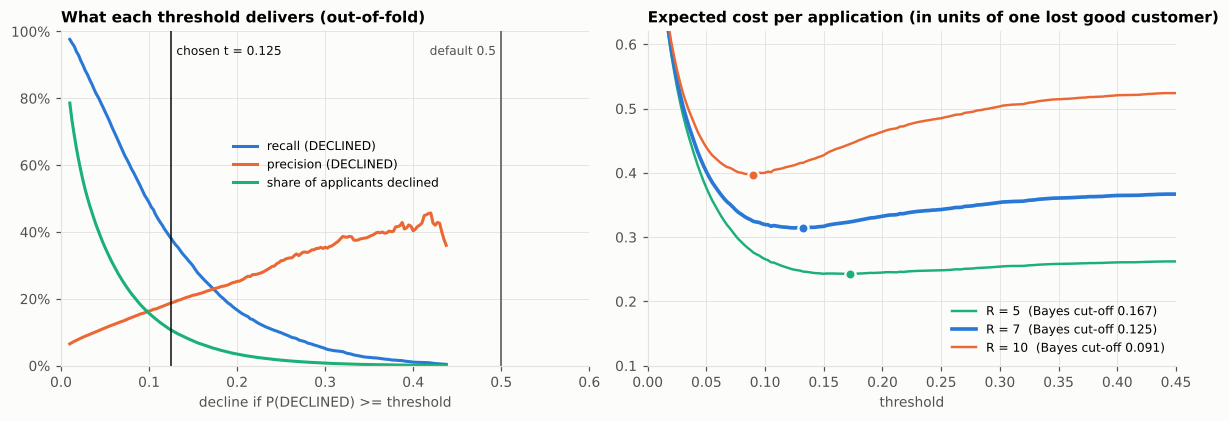

In [23]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.9))
ax = axs[0]
for col, colr, lbl in [("recall_declined", C["blue"], "recall (DECLINED)"), ("precision_declined", C["orange"], "precision (DECLINED)"), ("share_declined", C["aqua"], "share of applicants declined")]:
    ok = (sweep["tp"] + sweep["fp"]) >= 50                       # precision is noise once almost nobody is declined
    ax.plot(sweep.loc[ok, "threshold"], sweep.loc[ok, col], color=colr, label=lbl)
ax.axvline(THRESHOLD, color=C["ink"], lw=1); ax.text(THRESHOLD + 0.006, 0.93, f"chosen t = {THRESHOLD}", fontsize=8, color=C["ink"])
ax.axvline(0.5, color=C["ink2"], lw=1); ax.text(0.494, 0.93, "default 0.5", fontsize=8, color=C["ink2"], ha="right")
ax.set(title="What each threshold delivers (out-of-fold)", xlabel="decline if P(DECLINED) >= threshold", xlim=(0, 0.6), ylim=(0, 1)); pct(ax); ax.legend(fontsize=8, loc="center", bbox_to_anchor=(0.52, 0.6))
ax = axs[1]
for R, colr in [(5, C["aqua"]), (7, C["blue"]), (10, C["orange"])]:
    c = cost(R) / len(y_tr); ax.plot(sweep["threshold"], c, color=colr, lw=2.4 if R == 7 else 1.6, label=f"R = {R}  (Bayes cut-off {1/(1+R):.3f})")
    i = int(np.argmin(c)); ax.scatter([sweep["threshold"][i]], [c[i]], s=45, color=colr, edgecolor=C["surface"], linewidth=1.5, zorder=3)
ax.set(title="Expected cost per application (in units of one lost good customer)", xlabel="threshold", xlim=(0, 0.45), ylim=(0.1, 0.62)); ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); save(fig, "fig09_threshold")

**Threshold decision.** The cost-minimising cut-off found empirically sits next to the theoretical value 1/(1+R) for every ratio tried — independent confirmation that the probabilities are calibrated. With **R = 7 the threshold is 0.125**, which is also close to the cut-off that maximises F1 on the DECLINED class, so two unrelated criteria agree. The sensitivity table is the menu for ABC Credit's risk committee: a ratio of 10 buys more recall at the price of declining many more good customers; the "balanced" default (R ≈ 18) would decline about a third of all applicants.

## 12. Hold-out evaluation

The tuned pipeline is fitted on the full training split and applied **once** to the 20% hold-out with the threshold fixed in Section 11. DECLINED is the positive class throughout: a true positive is a risky application correctly declined; recall (DECLINED) is the share of historically declined applications the model catches.

In [24]:
model_ho = tuned().fit(X_tr, y_tr)
p_ho = model_ho.predict_proba(X_ho)[:, 1]
yh = y_ho.values
fpr, tpr, _ = roc_curve(yh, p_ho)
ho_rank = {**rank_metrics(yh, p_ho), "gini": 2 * roc_auc_score(yh, p_ho) - 1, "ks": float((tpr - fpr).max()),
           "brier_baseline": float(yh.mean() * (1 - yh.mean())), "log_loss_baseline": float(log_loss(yh, np.full(len(yh), yh.mean())))}
ho = at_threshold(yh, p_ho, THRESHOLD)

# Benchmarks, all fixed on training data only
ltv_ho = F.basic_clean(X_ho)["LTV"].fillna(0).values
ltv_cut = float(np.quantile(ltv_tr, 1 - chosen_oof["share_declined"]))          # LTV rule declining the same share of applicants
lr = candidates["Logistic regression"].fit(X_tr, y_tr); p_lr = lr.predict_proba(X_ho)[:, 1]
bench = pd.DataFrame({
 "LightGBM (this model)": ho, "Always approve": at_threshold(yh, np.zeros(len(yh)), THRESHOLD),
 f"Rule: decline if LTV > {ltv_cut:.1f}%": at_threshold(yh, ltv_ho, ltv_cut + 1e-9),
 "Logistic regression (same threshold)": at_threshold(yh, p_lr, THRESHOLD)}).T
show = ["share_declined", "accuracy", "precision_declined", "recall_declined", "f1_declined", "precision_approved", "recall_approved", "balanced_accuracy", "mcc"]
display(bench[show].astype(float).style.format("{:.1%}").format({"f1_declined": "{:.3f}", "mcc": "{:.3f}"}))
print("Ranking / calibration on the hold-out:", {k: round(v, 4) for k, v in ho_rank.items()})
print(f"Confusion matrix at t = {THRESHOLD}:  TP {ho['tp']:,}  FN {ho['fn']:,}  FP {ho['fp']:,}  TN {ho['tn']:,}")

rng = np.random.default_rng(SEED); boot = []
for _ in range(400 if not FAST else 50):
    i = rng.integers(0, len(yh), len(yh)); m = at_threshold(yh[i], p_ho[i], THRESHOLD)
    boot.append([roc_auc_score(yh[i], p_ho[i]), average_precision_score(yh[i], p_ho[i]), m["recall_declined"], m["precision_declined"], m["accuracy"], m["f1_declined"]])
ci = pd.DataFrame(np.percentile(boot, [2.5, 97.5], axis=0).T, index=["roc_auc", "pr_auc", "recall_declined", "precision_declined", "accuracy", "f1_declined"], columns=["ci_low", "ci_high"])
display(ci.style.format("{:.3f}"))
RESULTS["holdout"] = {"ranking": ho_rank, "at_threshold": ho, "benchmarks": bench[show + ["tp", "fp", "fn", "tn"]].astype(float).round(5).reset_index().rename(columns={"index": "model"}).to_dict("records"),
                      "ltv_rule_cut": ltv_cut, "ci95": ci.round(4).to_dict("index")}

,share_declined,accuracy,precision_declined,recall_declined,f1_declined,precision_approved,recall_approved,balanced_accuracy,mcc
LightGBM (this model),0.106817,0.882114,0.194301,0.394737,0.260,0.964371,0.909162,0.651949,0.220
Always approve,0.000000,0.947422,0.000000,0.000000,0.000,0.947422,1.000000,0.500000,0.000
Rule: decline if LTV > 90.0%,0.107278,0.871968,0.148323,0.302632,0.199,0.958927,0.903563,0.603098,0.149
Logistic regression (same threshold),0.085693,0.895120,0.194833,0.317544,0.241,0.960755,0.927174,0.622359,0.195


Ranking / calibration on the hold-out: {'roc_auc': 0.7909, 'pr_auc': 0.1878, 'log_loss': 0.1766, 'brier': 0.0462, 'mean_p': 0.0526, 'gini': 0.5818, 'ks': 0.4362, 'brier_baseline': 0.0498, 'log_loss_baseline': 0.206}
Confusion matrix at t = 0.125:  TP 450  FN 690  FP 1,866  TN 18,676


,ci_low,ci_high
roc_auc,0.779,0.804
pr_auc,0.169,0.210
recall_declined,0.369,0.425
precision_declined,0.179,0.212
accuracy,0.878,0.887
f1_declined,0.242,0.281


In [25]:
# Alternative operating points (all thresholds fixed in advance from the cost ratio) and the decile view
ops = pd.DataFrame([{"operating_point": name, "cost_ratio_R": R, **at_threshold(yh, p_ho, 1 / (1 + R))} for name, R in
                    [("Conservative", 5), ("Chosen", COST_RATIO), ("Recall-priority", 10), ("'Balanced' weighting equivalent", round(ratio, 1))]])
display(ops[["operating_point", "cost_ratio_R", "threshold", "share_declined", "accuracy", "precision_declined", "recall_declined", "f1_declined"]]
        .style.format({"threshold": "{:.3f}", "share_declined": "{:.1%}", "accuracy": "{:.1%}", "precision_declined": "{:.1%}", "recall_declined": "{:.1%}", "f1_declined": "{:.3f}"}))
dec = pd.DataFrame({"p": p_ho, "y": yh}); dec["decile"] = 10 - pd.qcut(dec["p"].rank(method="first"), 10, labels=False)
lift = dec.groupby("decile").agg(n=("y", "size"), declined=("y", "sum"), rate=("y", "mean"), mean_p=("p", "mean"))
lift["cum_share_of_declines"] = lift["declined"].cumsum() / lift["declined"].sum(); lift["lift"] = lift["rate"] / yh.mean()
display(lift.style.format({"rate": "{:.1%}", "mean_p": "{:.1%}", "cum_share_of_declines": "{:.1%}", "lift": "{:.2f}"}))
RESULTS["holdout"]["operating_points"] = ops.round(5).to_dict("records")
RESULTS["holdout"]["deciles"] = lift.round(5).reset_index().to_dict("records")

,operating_point,cost_ratio_R,threshold,share_declined,accuracy,precision_declined,recall_declined,f1_declined
0,Conservative,5.000000,0.167,5.8%,91.6%,23.1%,25.4%,0.242
1,Chosen,7.000000,0.125,10.7%,88.2%,19.4%,39.5%,0.260
2,Recall-priority,10.000000,0.091,18.0%,82.4%,15.7%,53.5%,0.242
3,'Balanced' weighting equivalent,18.000000,0.053,33.9%,68.7%,11.6%,74.6%,0.200


,n,declined,rate,mean_p,cum_share_of_declines,lift
decile,,,,,,
1,2169,432,19.9%,19.6%,37.9%,3.79
2,2168,206,9.5%,10.4%,56.0%,1.81
3,2168,160,7.4%,7.1%,70.0%,1.40
4,2168,125,5.8%,5.1%,81.0%,1.10
5,2168,84,3.9%,3.7%,88.3%,0.74
6,2168,51,2.4%,2.6%,92.8%,0.45
7,2168,40,1.8%,1.8%,96.3%,0.35
8,2168,28,1.3%,1.2%,98.8%,0.25
9,2168,8,0.4%,0.7%,99.5%,0.07


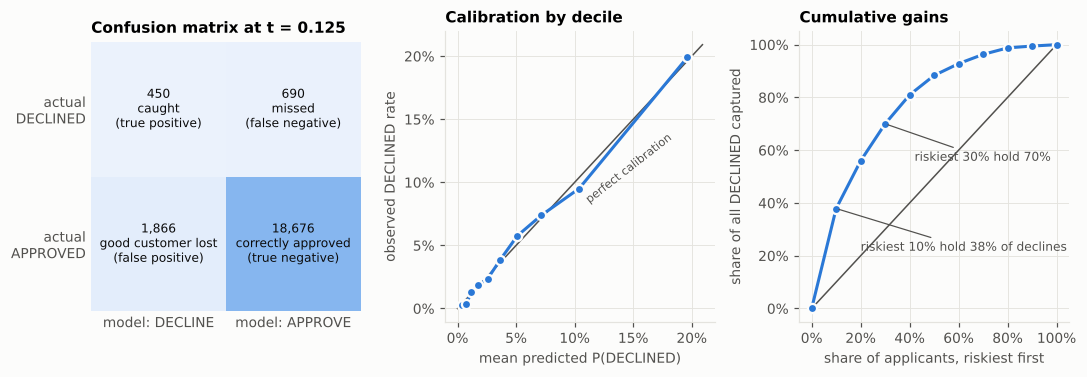

In [26]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3.5))
ax = axs[0]; cm = np.array([[ho["tp"], ho["fn"]], [ho["fp"], ho["tn"]]])
ax.imshow(cm, cmap=matplotlib.colors.LinearSegmentedColormap.from_list("b", ["#eef4fd", "#86b6ef"]), vmin=0, vmax=cm.max()); ax.grid(False)
lbl = [["caught\n(true positive)", "missed\n(false negative)"], ["good customer lost\n(false positive)", "correctly approved\n(true negative)"]]
for i in range(2):
    for j in range(2): ax.text(j, i, f"{cm[i, j]:,}\n{lbl[i][j]}", ha="center", va="center", fontsize=8, color=C["ink"])
ax.set_xticks([0, 1], ["model: DECLINE", "model: APPROVE"]); ax.set_yticks([0, 1], ["actual\nDECLINED", "actual\nAPPROVED"])
ax.set_title(f"Confusion matrix at t = {THRESHOLD}"); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax = axs[1]; r = dec.assign(b=pd.qcut(dec["p"], 10, labels=False)).groupby("b").agg(pred=("p", "mean"), obs=("y", "mean"))
ax.plot([0, r.max().max() * 1.05], [0, r.max().max() * 1.05], color=C["ink2"], lw=1)
ax.plot(r["pred"], r["obs"], color=C["blue"], marker="o", ms=6, mec=C["surface"], mew=1.5)
ax.set(title="Calibration by decile", xlabel="mean predicted P(DECLINED)", ylabel="observed DECLINED rate"); pct(ax, "x"); pct(ax, "y")
ax.text(r["pred"].max() * 0.55, r["obs"].max() * 0.42, "perfect calibration", fontsize=7.5, color=C["ink2"], rotation=38)
ax = axs[2]; x = np.arange(0, 11) / 10; g = np.r_[0, lift["cum_share_of_declines"].values]
ax.plot(x, x, color=C["ink2"], lw=1); ax.plot(x, g, color=C["blue"], marker="o", ms=6, mec=C["surface"], mew=1.5)
ax.annotate(f"riskiest 10% hold {g[1]:.0%} of declines", (0.1, g[1]), xytext=(0.2, g[1] - 0.16), fontsize=8, color=C["ink2"], arrowprops=dict(arrowstyle="-", color=C["ink2"], lw=0.8))
ax.annotate(f"riskiest 30% hold {g[3]:.0%}", (0.3, g[3]), xytext=(0.42, g[3] - 0.14), fontsize=8, color=C["ink2"], arrowprops=dict(arrowstyle="-", color=C["ink2"], lw=0.8))
ax.set(title="Cumulative gains", xlabel="share of applicants, riskiest first", ylabel="share of all DECLINED captured"); pct(ax, "x"); pct(ax, "y")
fig.tight_layout(); save(fig, "fig10_holdout")

**Reading the hold-out result.** Accuracy at the chosen cut-off is *below* the 94.7% of always-approve by design — the model gives up some accuracy on the majority class to catch risky applicants, which always-approve never does. Against a simple LTV rule that declines the same share of applicants, the model is better on accuracy, precision and recall at once. Precision on DECLINED is modest in absolute terms because the 15 available fields do not include what underwriters also saw (bureau history, verification), but it is several times the 5.3% base rate. Hold-out and out-of-fold figures agree closely, so the model generalises rather than memorises.

## 13. Explainability and fairness

**Global:** how much does performance fall when one question's answers are shuffled (permutation importance, hold-out), and how large are that question's average contributions to individual scores (TreeSHAP values computed by LightGBM)? **Local:** the same per-applicant contributions become the plain-language reason codes the chatbot shows. **Fairness:** outcomes are audited by gender (never a model input) and by age band.

,drop_pr_auc,drop_roc_auc,mean_abs_shap_log_odds
question,,,
price_and_loan,0.1130,0.2089,0.8604
pincode,0.0619,0.0537,0.3854
vehicle_model,0.0138,0.0141,0.1471
age,0.0104,0.0052,0.1298
active_loans,0.0098,0.0072,0.1214
net_salary,0.0018,0.0019,0.0502
employment_type,0.0015,0.0027,0.0698
qualification,0.0012,0.0007,0.0525


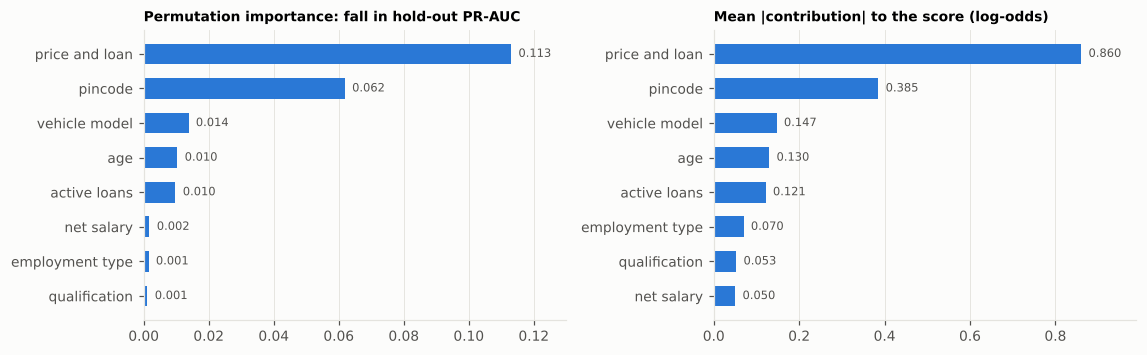

In [27]:
RAW_OF = {"price_and_loan": ["Loan_Amount", "LTV"], "pincode": ["Pincode", "Final_Tier"],
          "vehicle_model": ["Product_Code", "Make_Code", "Model_Description", "Model_Variant"], "active_loans": ["PAST_LOANS_ACTIVE"],
          "employment_type": ["Employment_Type"], "age": ["Age"], "qualification": ["Qualifications"], "net_salary": ["Net_salary"], "residence_type": ["Resident_Type"]}
base_ap, base_auc = average_precision_score(yh, p_ho), roc_auc_score(yh, p_ho)
rng = np.random.default_rng(SEED); imp = []
for q in final_questions:
    d_ap, d_auc = [], []
    for _ in range(5 if not FAST else 1):
        Xp = X_ho.copy(); perm = rng.permutation(len(Xp))
        Xp[RAW_OF[q]] = Xp[RAW_OF[q]].values[perm]
        pp = model_ho.predict_proba(Xp)[:, 1]
        d_ap.append(base_ap - average_precision_score(yh, pp)); d_auc.append(base_auc - roc_auc_score(yh, pp))
    imp.append({"question": q, "drop_pr_auc": np.mean(d_ap), "drop_roc_auc": np.mean(d_auc)})
imp = pd.DataFrame(imp).set_index("question")
Xt_ho = np.asarray(model_ho[:-1].transform(X_ho), dtype=float)
names = list(model_ho.named_steps["encode"].get_feature_names_out())
contrib = model_ho.named_steps["model"].booster_.predict(Xt_ho, pred_contrib=True)[:, :-1]
feat_q = {f: q for q in final_questions for f in QUESTIONS[q]}; feat_q.update({"price_vs_typical": "price_and_loan", "loan_to_annual_income": "net_salary"})
def q_of(n): return next((q for f, q in feat_q.items() if n == f or n.startswith(f + "_")), "other")
shap_q = pd.DataFrame(contrib, columns=names).T.groupby(q_of).sum().T.abs().mean()
imp["mean_abs_shap_log_odds"] = shap_q
imp = imp.sort_values("drop_pr_auc", ascending=False); display(imp.style.format("{:.4f}"))
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
for ax, col, title in [(axs[0], "drop_pr_auc", "Permutation importance: fall in hold-out PR-AUC"), (axs[1], "mean_abs_shap_log_odds", "Mean |contribution| to the score (log-odds)")]:
    s = imp[col].sort_values(); ax.barh([i.replace("_", " ") for i in s.index], s.values, height=0.6, color=C["blue"]); ax.grid(axis="y", visible=False)
    for i, v in enumerate(s.values): ax.text(v + s.max() * 0.02, i, f"{v:.3f}", va="center", fontsize=7.5, color=C["ink2"])
    ax.set_xlim(0, s.max() * 1.15); ax.set_title(title, fontsize=9)
fig.tight_layout(); save(fig, "fig11_importance")
RESULTS["importance"] = imp.round(5).reset_index().to_dict("records")

In [28]:
aud = pd.DataFrame({"y": yh, "p": p_ho, "d": p_ho >= THRESHOLD, "Gender": X_ho["Gender"].values,
                    "age": pd.to_numeric(X_ho["Age"], errors="coerce").values})
aud["Age band"] = pd.cut(aud["age"], [17, 25, 35, 45, 60, 100], labels=["18-25", "26-35", "36-45", "46-60", "61+"])
def group_audit(key):
    g = aud.groupby(key, observed=True)
    return pd.DataFrame({"n": g.size(), "actual_decline_rate": g["y"].mean(), "mean_predicted_p": g["p"].mean(), "model_decline_rate": g["d"].mean(),
        "approval_rate": 1 - g["d"].mean(), "recall_declined": g.apply(lambda t: t.loc[t.y == 1, "d"].mean()),
        "false_decline_rate": g.apply(lambda t: t.loc[t.y == 0, "d"].mean()), "roc_auc": g.apply(lambda t: roc_auc_score(t.y, t.p) if t.y.nunique() > 1 else np.nan)})
fair = pd.concat({"Gender": group_audit("Gender"), "Age band": group_audit("Age band")})
display(fair.style.format("{:.1%}").format({"n": "{:,}", "roc_auc": "{:.3f}"}))
di = lambda t: t["approval_rate"].min() / t["approval_rate"].max()
print(f"Disparate-impact ratio (lowest / highest approval rate): gender {di(fair.loc['Gender']):.3f}, age bands 18-60 {di(fair.loc['Age band'].drop('61+', errors='ignore')):.3f}  (0.8 is the common four-fifths benchmark)")
RESULTS["fairness"] = {"table": fair.round(5).reset_index().rename(columns={"level_0": "attribute", "level_1": "group"}).to_dict("records"),
                       "di_gender": float(di(fair.loc["Gender"])), "di_age": float(di(fair.loc["Age band"].drop("61+", errors="ignore")))}

Disparate-impact ratio (lowest / highest approval rate): gender 0.996, age bands 18-60 0.924  (0.8 is the common four-fifths benchmark)


**Interpretation.** LTV (from the price and loan questions) and the pincode area dominate; active loans, vehicle model and age follow; education, employment and income add little individually — consistent with Section 9. Approval rates by **gender** are practically identical although gender is not used, so there is no evidence of gender disparity. By **age**, younger applicants are declined more often; this follows a real difference in historical decline rates, but the model amplifies it somewhat, which should be monitored. **Pincode** is the second-strongest driver and can proxy for income or community: it is deliberately coarsened to the 3-digit district, and approval rates by region should be reviewed periodically.

## 14. Final model, artifacts and robustness test

With every design choice fixed, the same configuration is refitted on **all** labelled rows (training + hold-out) for deployment and for scoring ABC Credit's hidden test set. Saved together: the pipeline (`model_final.joblib`), its metadata (`model_meta.json`: version, threshold, features, questions, metrics, data hash) and the master data the chatbot uses to derive fields instead of asking for them (`reference_data.json`).

In [29]:
final = tuned().fit(X, y)
joblib.dump(final, "artifacts/model_final.joblib", compress=3)

clean_all = F.basic_clean(X)
known = clean_all[clean_all["Model_Description"] != "MISSING"]
pretty = lambda s: (s.title().replace("Bsvi", "BS6").replace("Tvs", "TVS").replace("Iqube", "iQube").replace("Xl ", "XL ").replace("Rtr", "RTR")
                    .replace("Abs", "ABS").replace("Cc", "cc").replace("Sxc", "SXC").replace("Zx", "ZX").replace("Es ", "ES ").replace("Hd ", "HD ").replace("Its", "ITS"))
catalogue = {}
for desc, g in known.groupby("Model_Description"):
    catalogue[desc] = {"Make_Code": g["Make_Code"].mode()[0], "Model_Variant": g["Model_Variant"].mode()[0], "Product_Code": g["Product_Code"].mode()[0],
                       "typical_price": int(round(g["vehicle_value"].median() / 500) * 500), "n": int(len(g)), "display": pretty(desc)}
tier_ok = clean_all[clean_all["Final_Tier"].notna()]
reference = {"vehicle_catalogue": catalogue,
             "pincode_tier": {str(int(k)): v for k, v in tier_ok.groupby(X.loc[tier_ok.index, "Pincode"])["Final_Tier"].first().items()},
             "pin3_tier": {k: v for k, v in tier_ok.groupby("pin3")["Final_Tier"].agg(lambda s: s.mode()[0]).items()}}
json.dump(reference, open("artifacts/reference_data.json", "w"))

SLOTS_OF = {"vehicle_model": ["vehicle_model"], "price_and_loan": ["on_road_price", "loan_amount"], "pincode": ["pincode", "area_type"], "age": ["age"],
            "employment_type": ["employment_type"], "net_salary": ["net_salary"], "active_loans": ["active_loans"], "qualification": ["qualification"],
            "residence_type": ["residence_type"]}
chatbot_slots = [s for q in final_questions for s in SLOTS_OF[q]]
SECONDS = {"consent": 15, "vehicle_model": 30, "on_road_price": 12, "loan_amount": 15, "pincode": 12, "age": 8, "employment_type": 8, "net_salary": 15,
           "active_loans": 6, "qualification": 8, "residence_type": 6, "summary": 30, "decision": 20}     # planning assumptions, to be validated in a pilot
asked = [s for s in chatbot_slots if s != "area_type"]
typical_s = SECONDS["consent"] + sum(SECONDS[s] for s in asked) + SECONDS["summary"] + SECONDS["decision"]
X_MINUTES, Y_SECONDS = int(np.ceil(typical_s * 1.3 / 60)), 2
meta = {"model_version": "abc-credit-lgbm-2026-11-13", "trained_on_rows": int(len(X)), "positive_class": "DECLINED", "threshold": THRESHOLD,
        "cost_ratio": COST_RATIO, "lgbm_params": BEST, "model_features": KEEP, "questions": final_questions, "chatbot_slots": chatbot_slots,
        "fields_asked": len(asked), "age_policy": [F.AGE_MIN, F.AGE_MAX], "x_minutes": X_MINUTES, "y_seconds": Y_SECONDS, "typical_seconds": typical_s,
        "data_sha256": hashlib.sha256(open(DATA, "rb").read()).hexdigest(),
        "holdout": {k: ho_rank[k] for k in ["roc_auc", "pr_auc", "gini", "ks", "brier"]} | {k: ho[k] for k in ["accuracy", "precision_declined", "recall_declined", "f1_declined", "share_declined"]},
        "libraries": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__, "pandas": pd.__version__, "numpy": np.__version__}}
json.dump(meta, open("artifacts/model_meta.json", "w"), indent=1)
print(f"saved: model_final.joblib ({os.path.getsize('artifacts/model_final.joblib') / 1e6:.1f} MB), model_meta.json, reference_data.json "
      f"({len(catalogue)} vehicle models, {len(reference['pincode_tier']):,} pincodes)")
print(f"chatbot asks {len(asked)} fields: {asked}\nplanning time {typical_s}s ({typical_s / 60:.1f} min) -> X = {X_MINUTES} minutes; Y = {Y_SECONDS} seconds")
RESULTS["deployment"] = {k: meta[k] for k in ["model_version", "threshold", "chatbot_slots", "fields_asked", "x_minutes", "y_seconds", "typical_seconds", "trained_on_rows"]}
RESULTS["deployment"]["time_budget"] = {s: SECONDS[s] for s in ["consent"] + asked + ["summary", "decision"]}
RESULTS["deployment"]["catalogue_models"] = len(catalogue)

saved: model_final.joblib (0.3 MB), model_meta.json, reference_data.json (87 vehicle models, 13,981 pincodes)
chatbot asks 9 fields: ['on_road_price', 'loan_amount', 'pincode', 'vehicle_model', 'active_loans', 'employment_type', 'age', 'qualification', 'net_salary']
planning time 179s (3.0 min) -> X = 4 minutes; Y = 2 seconds


In [30]:
# Robustness: categories never seen in training, impossible values and an all-null row must still be scored
loaded = joblib.load("artifacts/model_final.joblib")
weird = {"ID": 900001, "Qualifications": "DIPLOMA", "Employment_Type": "GIG", "Age": "abc", "Pincode": 999999, "Gender": "Other", "Product_Code": "EV3",
         "Loan_Amount": 80000, "LTV": 82.5, "Resident_Type": "X", "Net_salary": -5, "Final_Tier": "08 Village", "Make_Code": "ORBITER",
         "Model_Description": "TVS ORBITER 2027 â€“ LAUNCH EDITION", "Model_Variant": "ORBITER 3KWH", "PAST_LOANS_ACTIVE": "UNKNOWN"}
nulls = {k: None for k in weird}
p_rob = loaded.predict_proba(pd.DataFrame([weird, nulls]))[:, 1]
assert np.all((p_rob > 0) & (p_rob < 1))
print("unseen-category row -> P(DECLINED) =", round(float(p_rob[0]), 4), "| all-null row ->", round(float(p_rob[1]), 4), "| no error raised")
assert np.allclose(loaded.predict_proba(X.head(200))[:, 1], final.predict_proba(X.head(200))[:, 1])
RESULTS["robustness"] = {"unseen_row_p": float(p_rob[0]), "null_row_p": float(p_rob[1])}

unseen-category row -> P(DECLINED) = 0.0147 | all-null row -> 0.0183 | no error raised


## 15. Predictions file

`predict.py` scores any file with the 16 input columns and writes one row per `ID` with the `Decision` label (APPROVED / DECLINED, as in the training file) and the model probability. ABC Credit's hidden test file was not shared, so two outputs are produced here:

* `outputs/predictions_holdout.csv` — predictions for our own 20% hold-out, made by the model that never saw those rows (the honest stand-in for the hidden set, and the file behind the metrics of Section 12);
* a smoke test of `predict.py` on a small file that includes unseen categories and missing values, to show the scorer cannot be broken by the hidden file.

To score the real test file: `python predict.py --test <test.csv> --out predictions.csv`.

In [31]:
%%writefile predict.py
"""Score a file of loan applications with the saved pipeline.

    python predict.py --test path/to/test.csv --out predictions.csv

Output: one row per ID with Decision (APPROVED / DECLINED) and Probability_DECLINED.
Every row with an ID is scored - unseen categories, blanks and impossible values cannot break it.
"""
import argparse
import json

import joblib
import pandas as pd

import abc_features  # noqa: F401  (needed to un-pickle the pipeline)


def score_file(test_path, out_path, model_path="artifacts/model_final.joblib", meta_path="artifacts/model_meta.json"):
    pipe, meta = joblib.load(model_path), json.load(open(meta_path))
    test = pd.read_csv(test_path, low_memory=False)
    test = test[test["ID"].notna()].copy()
    p = pipe.predict_proba(test.drop(columns=["Decision"], errors="ignore"))[:, 1]
    out = pd.DataFrame({"ID": test["ID"].astype(int).values,
                        "Decision": ["DECLINED" if v >= meta["threshold"] else "APPROVED" for v in p],
                        "Probability_DECLINED": p.round(6)})
    out.to_csv(out_path, index=False)
    return out


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--test", required=True)
    ap.add_argument("--out", default="predictions.csv")
    a = ap.parse_args()
    res = score_file(a.test, a.out)
    print(f"{len(res):,} rows scored -> {a.out}", res["Decision"].value_counts().to_dict())

Overwriting predict.py


In [32]:
pred_ho = pd.DataFrame({"ID": X_ho["ID"].values, "Decision": np.where(p_ho >= THRESHOLD, "DECLINED", "APPROVED"), "Probability_DECLINED": p_ho.round(6)}).sort_values("ID")
pred_ho.to_csv("outputs/predictions_holdout.csv", index=False)
print("predictions_holdout.csv:", len(pred_ho), "rows,", pred_ho["ID"].is_unique and "unique IDs,", pred_ho["Decision"].value_counts().to_dict())
display(pred_ho.head())

import predict; importlib.reload(predict)
sample = raw.sample(300, random_state=SEED).drop(columns=["Decision"])
sample = pd.concat([sample, pd.DataFrame([weird, {**nulls, "ID": 900002}])], ignore_index=True)
sample.to_csv("outputs/sample_test_file.csv", index=False)
out = predict.score_file("outputs/sample_test_file.csv", "outputs/predictions_sample.csv")
print("predict.py smoke test:", len(out), "rows in ->", len(out), "rows out;", out["Decision"].value_counts().to_dict())
RESULTS["predictions"] = {"holdout_rows": int(len(pred_ho)), "holdout_declined": int((pred_ho.Decision == "DECLINED").sum())}

predictions_holdout.csv: 21682 rows, unique IDs, {'APPROVED': 19366, 'DECLINED': 2316}


,ID,Decision,Probability_DECLINED
4612,3,APPROVED,0.008183
21437,6,APPROVED,0.022972
4165,16,DECLINED,0.139163
4497,19,APPROVED,0.007074
15989,21,APPROVED,0.007856


predict.py smoke test: 302 rows in -> 302 rows out; {'APPROVED': 276, 'DECLINED': 26}


## 16. Scoring latency and results summary

Single-application scoring time of the saved pipeline (cleaning + encoding + LightGBM), the model's share of the chatbot's decision latency. The end-to-end figure — final input to decision message, including reason codes and logging — is measured by `chatbot/simulate.py`.

In [33]:
rows1 = [X.iloc[[i]] for i in np.random.default_rng(SEED).integers(0, len(X), 300)]
loaded.predict_proba(rows1[0]); ms = []
for r in rows1:
    t0 = time.perf_counter(); loaded.predict_proba(r); ms.append((time.perf_counter() - t0) * 1000)
lat = {"p50_ms": float(np.percentile(ms, 50)), "p95_ms": float(np.percentile(ms, 95)), "p99_ms": float(np.percentile(ms, 99)), "cpus": os.cpu_count()}
print("single-row pipeline scoring:", {k: round(v, 1) for k, v in lat.items()})
RESULTS["model_latency"] = lat
json.dump(RESULTS, open("outputs/results.json", "w"), indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
h = RESULTS["holdout"]
print(f'''
SUMMARY
  data            {load_log['rows_used']:,} usable applications, {load_log['decline_rate']:.2%} DECLINED
  questions       {final_questions}
  model           LightGBM {BEST}
  hold-out        ROC-AUC {h['ranking']['roc_auc']:.3f} | PR-AUC {h['ranking']['pr_auc']:.3f} | Gini {h['ranking']['gini']:.3f} | KS {h['ranking']['ks']:.3f}
  at t = {THRESHOLD}    accuracy {h['at_threshold']['accuracy']:.1%} | precision(DECLINED) {h['at_threshold']['precision_declined']:.1%} | recall(DECLINED) {h['at_threshold']['recall_declined']:.1%} | F1 {h['at_threshold']['f1_declined']:.3f} | declined {h['at_threshold']['share_declined']:.1%}
  X, Y            {X_MINUTES} minutes, {Y_SECONDS} seconds (p95)''')

single-row pipeline scoring: {'p50_ms': 38.0, 'p95_ms': 48.8, 'p99_ms': 61.0, 'cpus': 2}

SUMMARY
  data            108,409 usable applications, 5.26% DECLINED
  questions       ['price_and_loan', 'pincode', 'vehicle_model', 'active_loans', 'employment_type', 'age', 'qualification', 'net_salary']
  model           LightGBM {'reg_lambda': 5.0, 'num_leaves': 7, 'n_estimators': 700, 'min_child_samples': 50, 'learning_rate': 0.03, 'colsample_bytree': 0.9}
  hold-out        ROC-AUC 0.791 | PR-AUC 0.188 | Gini 0.582 | KS 0.436
  at t = 0.125    accuracy 88.2% | precision(DECLINED) 19.4% | recall(DECLINED) 39.5% | F1 0.260 | declined 10.7%
  X, Y            4 minutes, 2 seconds (p95)
